# 01 · Data understanding
Follows handbook section 3.3 (data description, exploration, quality checks), adapted to the
DSC data: 179,446 buildings, 116 features, target **EPC label** (8 ordered classes, A+ → G).

Only `fix_types()` is applied here (Step 0: correct column types). Nothing is filled or dropped,
so missing values stay visible. The cleaning itself happens in `02_data_preparation`.

In [2]:
print(repr(PASSWORD_FILE.read_text()))

'datasciencechallenge'


## Step 0 · Load the data and fix the column types

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

raw_train, raw_score = load_raw()          # first run decrypts the Excel files (slow), then cached
print("training:", raw_train.shape, "| scoring:", raw_score.shape)

training: (179446, 117) | scoring: (76906, 116)


Test what EPC+, EPC-, FincTrue means

In [19]:
t = data.assign(label=status)
et = "EPC type"

print("1. Region: is it a regional system?")
print(pd.crosstab(t[et], t["region"], normalize="index").round(3))

print("\n2. Age: is it linked to old vs. new buildings?")
print(t.groupby(et)[["builtyear", "builtyear_is_range"]].mean().round(3))
print(pd.crosstab(t[et], t["source of builtyear"], normalize="index").round(3))

print("\n3. Building kind: residential vs. other certificates?")
print(pd.crosstab(t[et], t["destination"], normalize="index").round(3))
print(pd.crosstab(t[et], t["part of whole building"], normalize="index").round(3))

print("\n4. Missingness: do the types come from different sources?")
cols = ["Price", "REAL_ESTATE_TYPE", "fed_address_id", "volume building", "garden surface"]
print(t[cols].isna().groupby(t[et]).mean().round(3))

print("\n5. Price: linked to sales or property value?")
print(t.groupby(et)["Price"].describe()[["count", "50%", "mean"]].round(0))

print("\n6. ID order: were the types added to the dataset separately?")
id_num = pd.to_numeric(raw_train["finc_id"].str.extract(r"(\d+)")[0], errors="coerce")
print(id_num.groupby(t[et]).describe()[["min", "50%", "max"]])

print("\n7. Same label pattern within one region? (separates 'region effect' from 'type effect')")
fl = t[t["region"] == "Flanders"]
print(pd.crosstab(fl[et], fl["label"], normalize="index")[[c for c in ORDER if c in fl["label"].unique()]].round(2))

1. Region: is it a regional system?
region     Brussels  Flanders  Wallonia
EPC type                               
EPC+          0.056     0.555     0.389
EPC-          0.062     0.609     0.329
Finc True     0.078     0.631     0.290

2. Age: is it linked to old vs. new buildings?
           builtyear  builtyear_is_range
EPC type                                
EPC+        1974.937               0.856
EPC-        1975.963               0.835
Finc True   1971.432               0.893
source of builtyear  building permit  image analysis  regional topo reference
EPC type                                                                     
EPC+                           0.042           0.786                    0.172
EPC-                           0.038           0.769                    0.193
Finc True                      0.048           0.822                    0.130

3. Building kind: residential vs. other certificates?
destination  mixed use  non-residential  residential  \
EPC type  

**Build year is stored as periods for most buildings.** Check the raw values *before* any conversion:
`pd.to_numeric` would turn "1930-1969" into NaN and fake 84% missing values.

In [3]:
print("Missing in raw file:", raw_train["builtyear"].isna().mean().round(3))
print(raw_train["builtyear"].astype(str).value_counts().head(25))

Missing in raw file: 0.0
builtyear
1930-1969    83957
1990-2009    36516
1970-1989    30163
2023          3100
2022          3050
2018          2318
2020          2161
2019          1957
2024          1896
2021          1819
2010          1427
2011          1383
2014          1370
2013          1303
2012          1296
2015          1278
2016          1267
2017          1207
2025          1143
<1930          835
Name: count, dtype: int64


In [4]:
data = fix_types(raw_train.drop(columns=[TARGET]))
status = raw_train[TARGET]

print(data.shape)
print("builtyear missing:", data["builtyear"].isna().mean().round(3))            # expect 0.0
print("builtyear_is_range:", data["builtyear_is_range"].mean().round(3))        # ~0.84: only a period is known

(179446, 118)
builtyear missing: 0.0
builtyear_is_range: 0.844


## Step 1 · Frequency distribution of the target

EPC label
A+     1389
A     12558
B     27600
C     35495
D     32934
E     23555
F     34028
G     11887
Name: count, dtype: int64
EPC label
A+    0.008
A     0.070
B     0.154
C     0.198
D     0.184
E     0.131
F     0.190
G     0.066
Name: proportion, dtype: float64


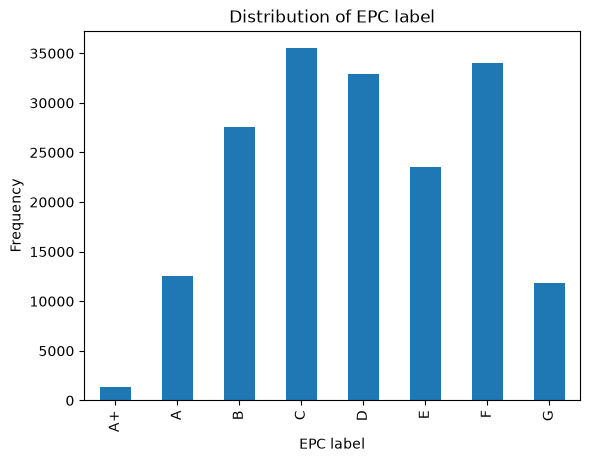

In [5]:
print(status.value_counts().reindex(ORDER))
print(status.value_counts(normalize=True).reindex(ORDER).round(3))

status.value_counts().reindex(ORDER).plot(kind="bar")
plt.title("Distribution of EPC label"); plt.xlabel("EPC label"); plt.ylabel("Frequency")
plt.show()

## Step 2 · Frequency distributions of categorical variables

In [6]:
categorical_vars = data.select_dtypes(exclude="number").columns
print(data[categorical_vars].nunique().sort_values().to_string())

floodrisk building - ogoz                                        1
built/unbuilt                                                    1
patrimony                                                        2
solarpanels                                                      2
swimming pool                                                    2
garden presence                                                  2
part of whole building                                           2
main building has multiple units                                 2
main building selection                                          2
nature                                                           2
region                                                           3
high voltage                                                     3
EPC type                                                         3
source of builtyear                                              3
floodrisk building - coastal                                  

--- finc_id (179446 categories) ---
finc_id
finc_179847    0.0
finc_288101    0.0
finc_152488    0.0
finc_211008    0.0
finc_208422    0.0
finc_028904    0.0
finc_106432    0.0
finc_275367    0.0
finc_051879    0.0
finc_229914    0.0
Name: proportion, dtype: float64
--- ZIP_COD (1144 categories) ---
ZIP_COD
9000    0.010
8400    0.008
1030    0.007
8800    0.007
4000    0.007
2800    0.007
1180    0.006
9100    0.006
1050    0.005
1070    0.005
Name: proportion, dtype: float64
--- REAL_ESTATE_TYPE (28 categories) ---
REAL_ESTATE_TYPE
Eéngezinswoning                                    0.779
Appartement / studio / flat / loft                 0.132
Huis                                               0.023
Residentiële opbrengswoning                        0.015
Handelhuis                                         0.011
Villa                                              0.009
Klassiek hoevegebouw                               0.006
Appartement                                        0.005
Resi

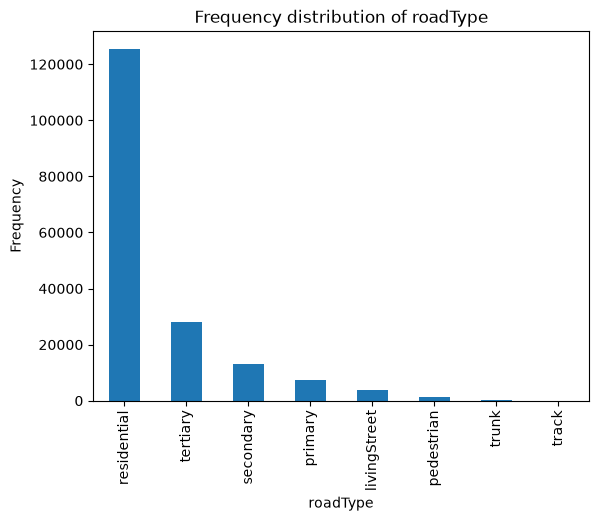

--- highway distance (17 categories) ---
highway distance
3km             0.141
2km             0.122
4km             0.120
moreThan10km    0.094
5km             0.093
1,5km           0.086
1km             0.069
6km             0.063
7km             0.046
8km             0.038
Name: proportion, dtype: float64


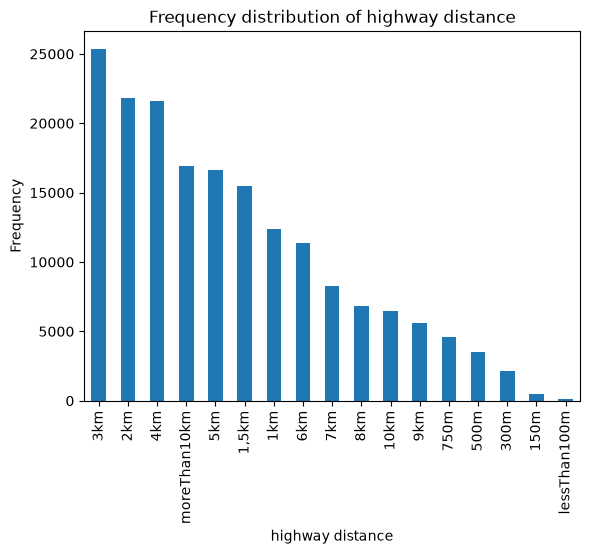

--- bus- or tram distance (10 categories) ---
bus- or tram distance
150m            0.318
300m            0.301
lessThan100m    0.236
500m            0.082
750m            0.030
1km             0.022
1,5km           0.007
2km             0.003
3km             0.001
4km             0.000
Name: proportion, dtype: float64


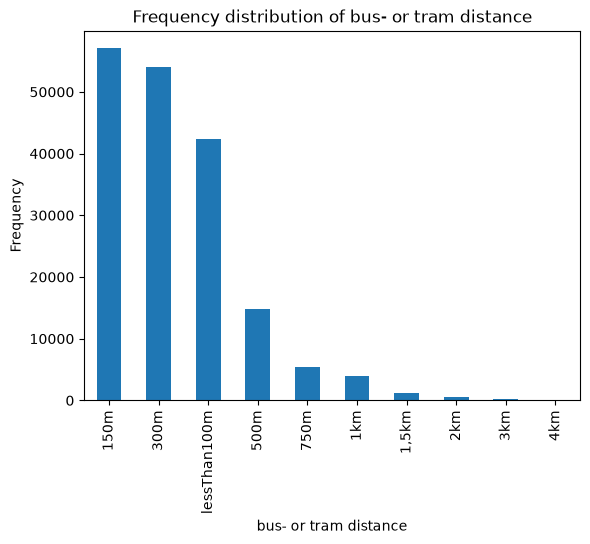

--- train distance (17 categories) ---
train distance
1km      0.135
2km      0.117
3km      0.115
1,5km    0.112
4km      0.083
5km      0.065
750m     0.063
500m     0.056
6km      0.046
300m     0.042
Name: proportion, dtype: float64


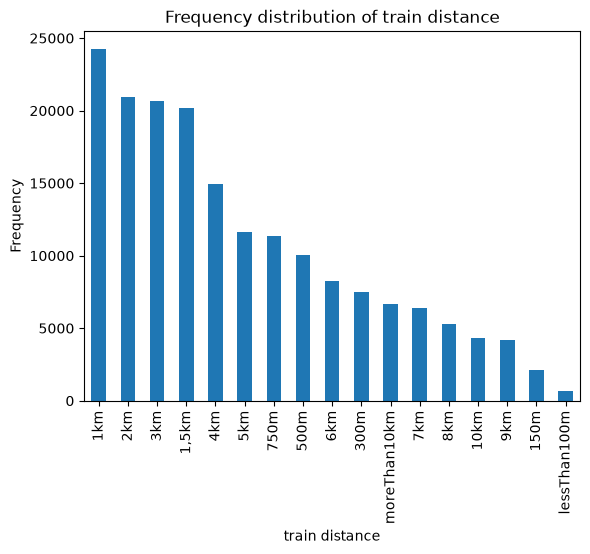

--- supermarket distance (17 categories) ---
supermarket distance
300m            0.177
500m            0.146
1km             0.145
750m            0.106
1,5km           0.094
2km             0.094
150m            0.073
3km             0.069
4km             0.034
lessThan100m    0.029
Name: proportion, dtype: float64


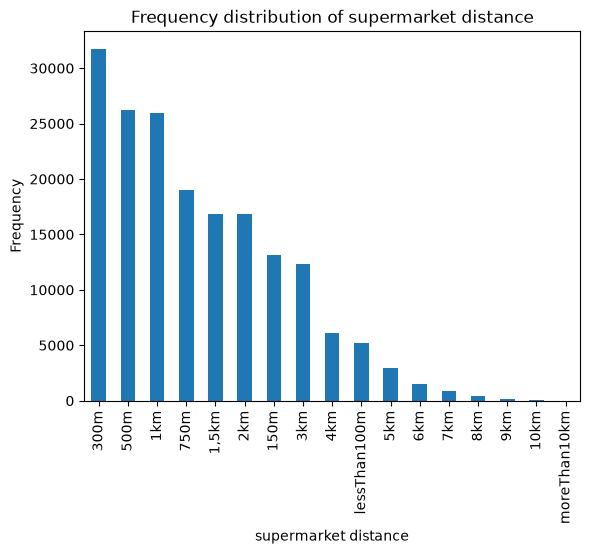

--- school distance (17 categories) ---
school distance
300m            0.259
500m            0.164
150m            0.140
1km             0.129
750m            0.104
1,5km           0.069
lessThan100m    0.056
2km             0.046
3km             0.022
4km             0.008
Name: proportion, dtype: float64


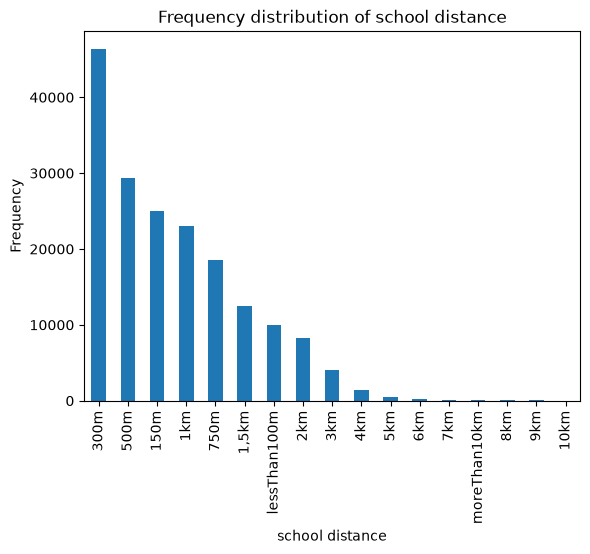

--- police station distance (17 categories) ---
police station distance
1km      0.156
3km      0.144
2km      0.143
1,5km    0.124
4km      0.097
750m     0.080
500m     0.077
300m     0.058
5km      0.052
6km      0.025
Name: proportion, dtype: float64


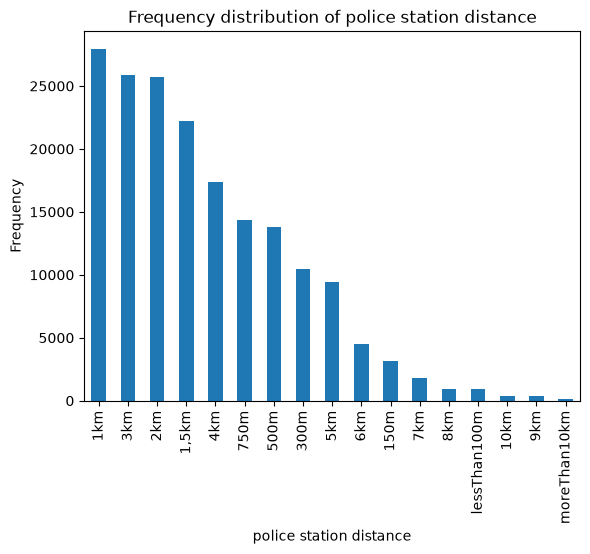

--- fire station distance (17 categories) ---
fire station distance
3km      0.167
2km      0.152
4km      0.117
1,5km    0.111
1km      0.102
5km      0.085
6km      0.061
7km      0.044
750m     0.041
500m     0.034
Name: proportion, dtype: float64


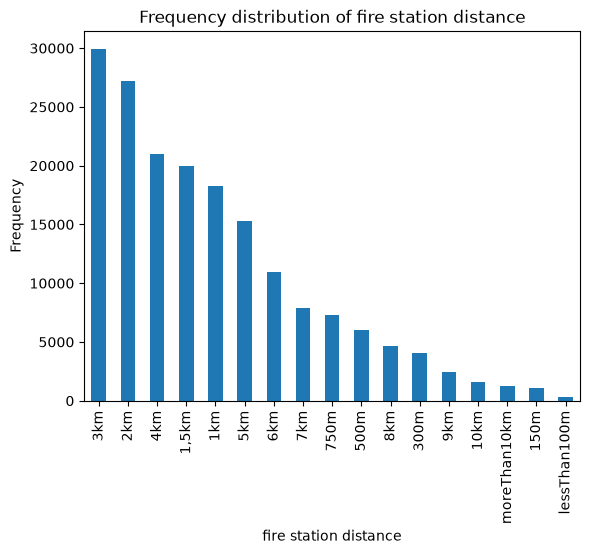

--- noise pollution roads (6 categories) ---
noise pollution roads
none          0.843
55-60dB(A)    0.072
60-65dB(A)    0.051
65-70dB(A)    0.028
70-75dB(A)    0.005
>=75dB(A)     0.000
Name: proportion, dtype: float64


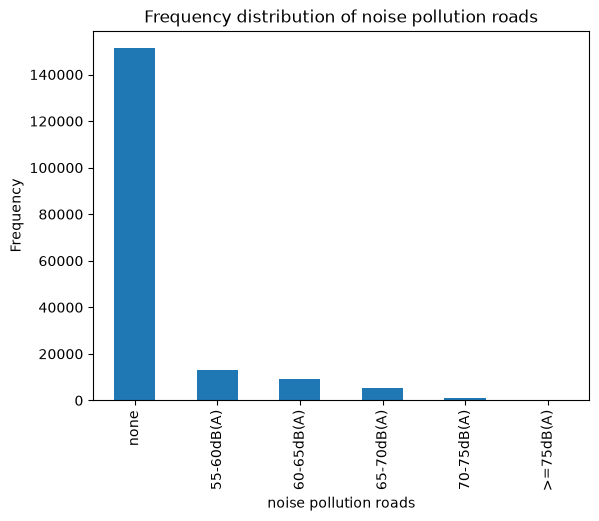

--- noise pollution railways (6 categories) ---
noise pollution railways
none          0.937
55-60dB(A)    0.033
65-70dB(A)    0.014
60-65dB(A)    0.012
70-75dB(A)    0.004
>=75dB(A)     0.000
Name: proportion, dtype: float64


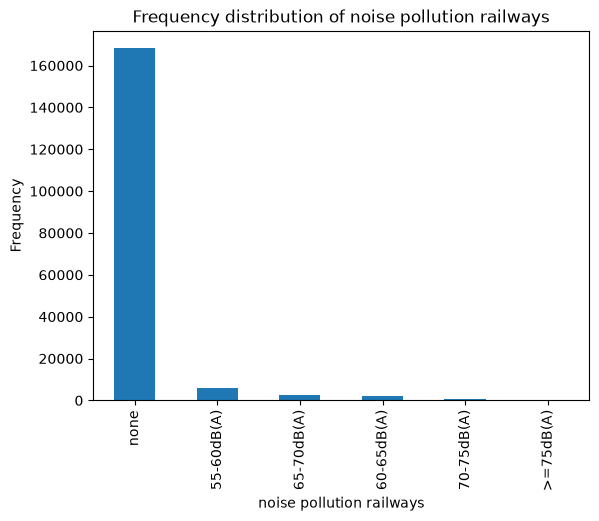

--- noise pollution air traffic (5 categories) ---
noise pollution air traffic
none          0.989
55-60dB(A)    0.008
60-65dB(A)    0.002
65-70dB(A)    0.001
70-75dB(A)    0.000
Name: proportion, dtype: float64


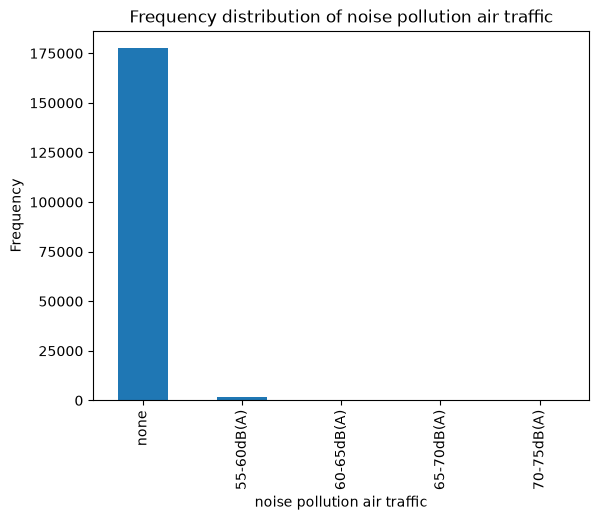

--- noise pollution industry (6 categories) ---
noise pollution industry
none          0.997
55-60dB(A)    0.002
60-65dB(A)    0.001
65-70dB(A)    0.000
70-75dB(A)    0.000
>=75dB(A)     0.000
Name: proportion, dtype: float64


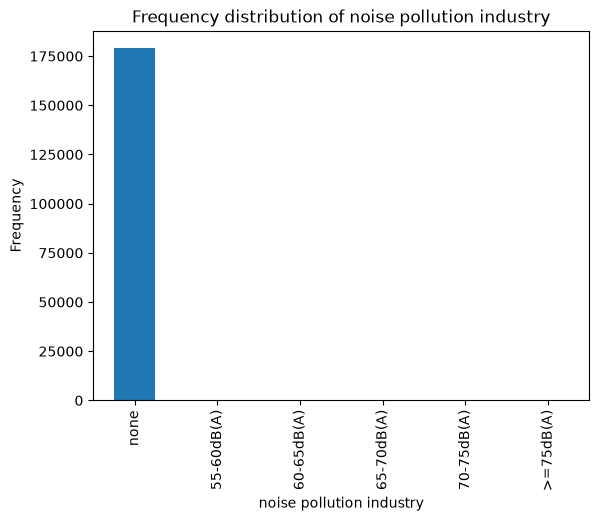

--- noise pollution combined (6 categories) ---
noise pollution combined
none          0.786
55-60dB(A)    0.100
60-65dB(A)    0.062
65-70dB(A)    0.042
70-75dB(A)    0.009
>=75dB(A)     0.000
Name: proportion, dtype: float64


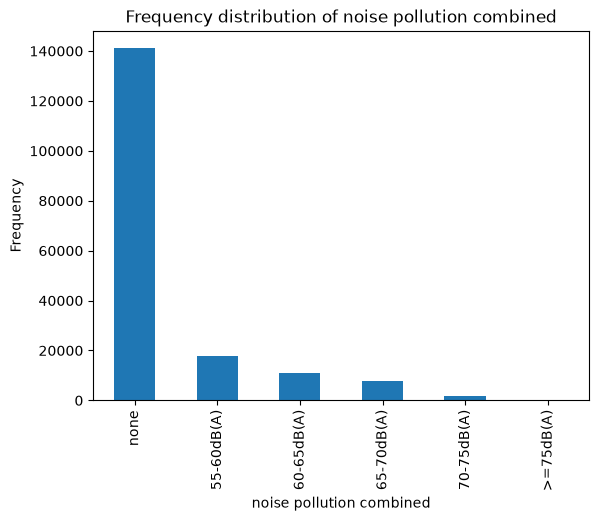

--- high voltage (3 categories) ---
high voltage
none     0.971
200m     0.026
above    0.003
Name: proportion, dtype: float64


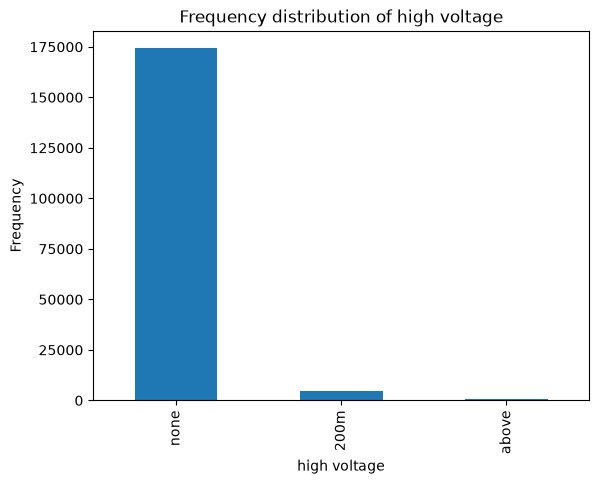

--- nature (2 categories) ---
nature
none    0.988
yes     0.012
Name: proportion, dtype: float64


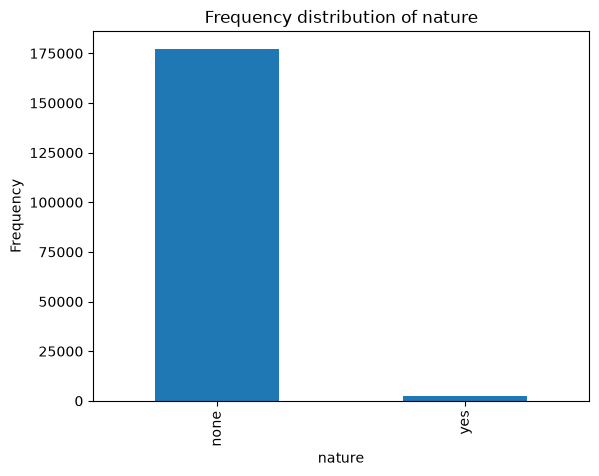

--- regional planning (729 categories) ---
regional planning
woongebied                                                          0.353
woonzone                                                            0.156
woongebied met landelijk karakter                                   0.144
typisch woongebied                                                  0.038
agrarisch gebied                                                    0.028
woongebied met landelijk karakter; agrarisch gebied                 0.028
woongebied met landelijk karakter; landbouwgebied                   0.025
woonuitbreidingsgebied                                              0.023
woongebieden met cultureel, historische en/of esthetische waarde    0.017
woongebied; agrarisch gebied                                        0.014
Name: proportion, dtype: float64
--- built/unbuilt (1 categories) ---
built/unbuilt
built    1.0
Name: proportion, dtype: float64


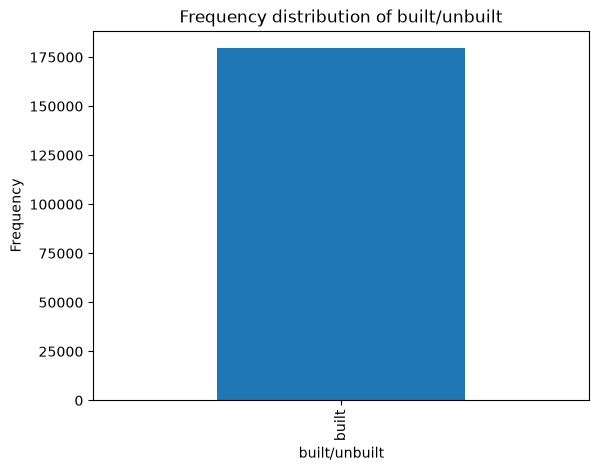

--- garden orientation (8 categories) ---
garden orientation
NW    0.143
SE    0.138
S     0.121
SW    0.121
W     0.121
NE    0.120
E     0.118
N     0.117
Name: proportion, dtype: float64


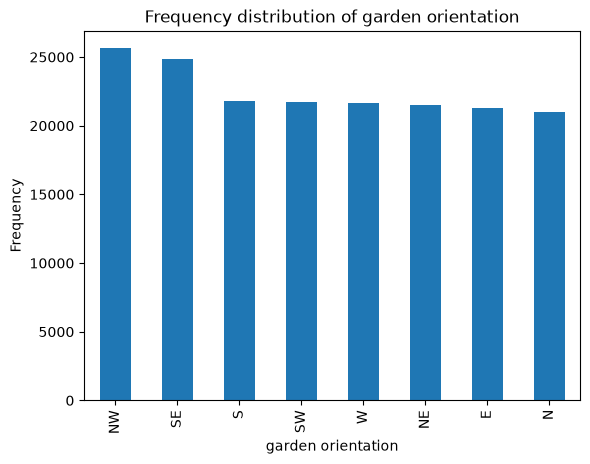

--- garden presence (2 categories) ---
garden presence
yes    0.913
no     0.087
Name: proportion, dtype: float64


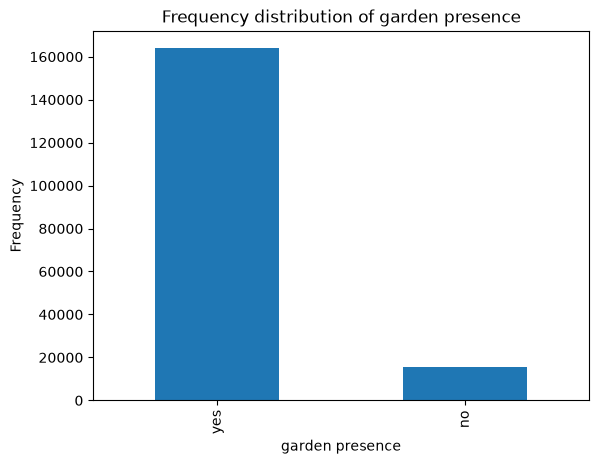

--- swimming pool (2 categories) ---
swimming pool
no     0.967
yes    0.033
Name: proportion, dtype: float64


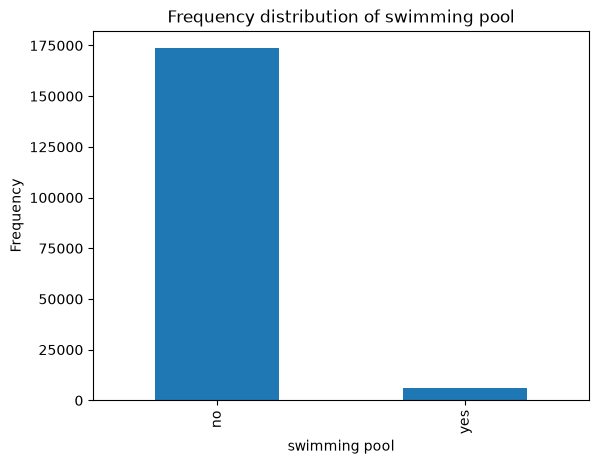

--- floodrisk parcel - coastal (4 categories) ---
floodrisk parcel - coastal
none      0.973
medium    0.011
low       0.010
high      0.006
Name: proportion, dtype: float64


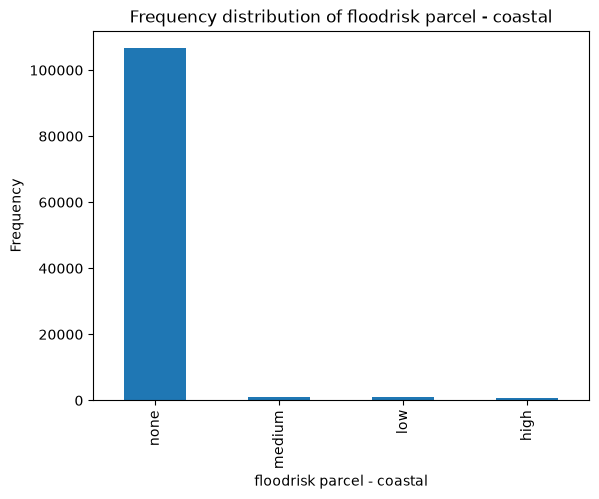

--- floodrisk parcel - fluvial (4 categories) ---
floodrisk parcel - fluvial
none      0.943
low       0.024
medium    0.018
high      0.015
Name: proportion, dtype: float64


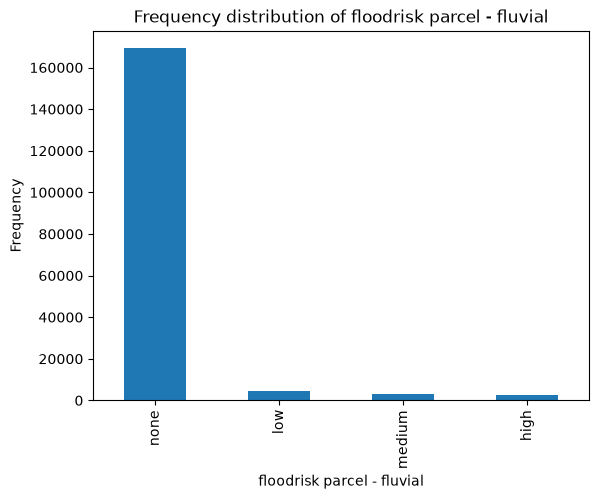

--- floodrisk parcel - pluvial (4 categories) ---
floodrisk parcel - pluvial
none      0.732
low       0.104
high      0.093
medium    0.070
Name: proportion, dtype: float64


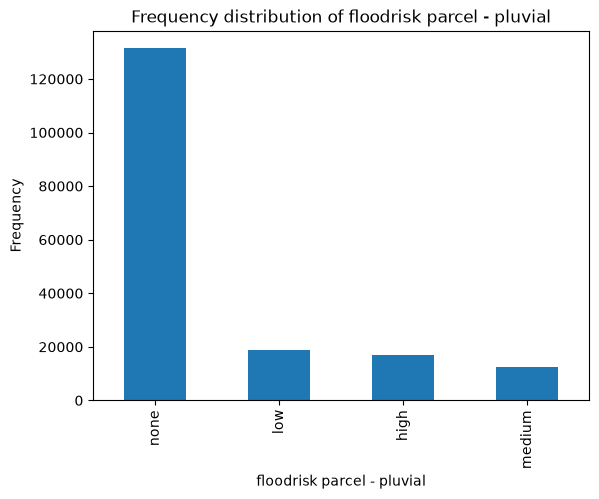

--- floodrisk parcel - combined (4 categories) ---
floodrisk parcel - combined
none      0.692
low       0.122
high      0.104
medium    0.083
Name: proportion, dtype: float64


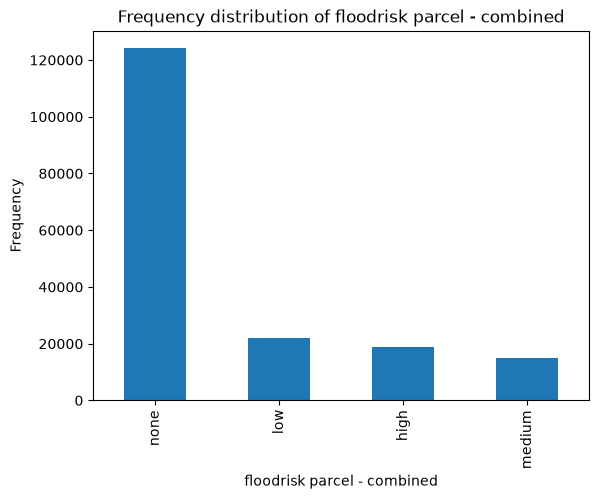

--- floodrisk parcel - waterdepth - fluvial_current_high (10 categories) ---
floodrisk parcel - waterdepth - fluvial_current_high
none                                0.989
Hauteur d'eau entre 0,3 et 1,3 m    0.003
Hauteur d'eau supérieure à 1,3 m    0.002
1-25cm                              0.001
25-50cm                             0.001
Hauteur d'eau entre 0 et 0,3 m      0.001
50-100cm                            0.001
Hauteur d'eau indéterminée          0.001
100-200cm                           0.000
>200cm                              0.000
Name: proportion, dtype: float64


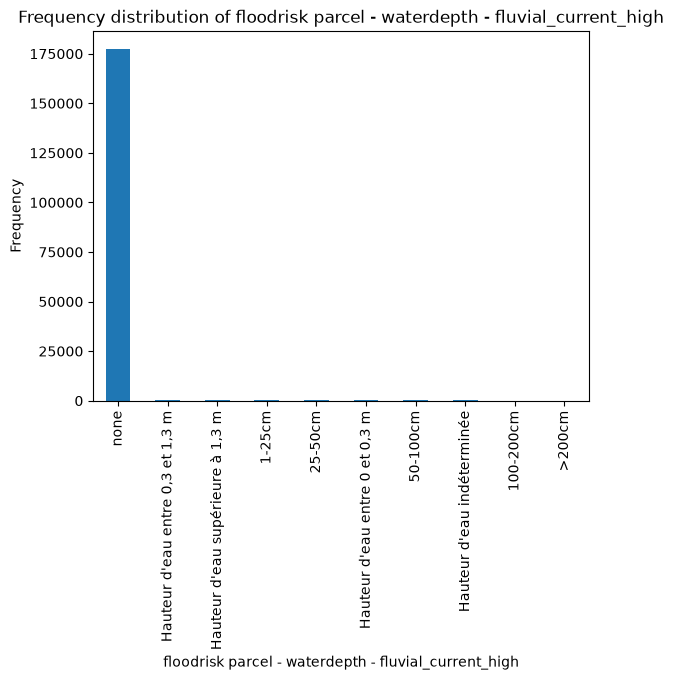

--- floodrisk parcel - waterdepth - fluvial_current_medium (10 categories) ---
floodrisk parcel - waterdepth - fluvial_current_medium
none                                0.982
Hauteur d'eau entre 0,3 et 1,3 m    0.004
Hauteur d'eau indéterminée          0.003
1-25cm                              0.003
25-50cm                             0.002
50-100cm                            0.002
Hauteur d'eau supérieure à 1,3 m    0.002
Hauteur d'eau entre 0 et 0,3 m      0.001
100-200cm                           0.001
>200cm                              0.000
Name: proportion, dtype: float64


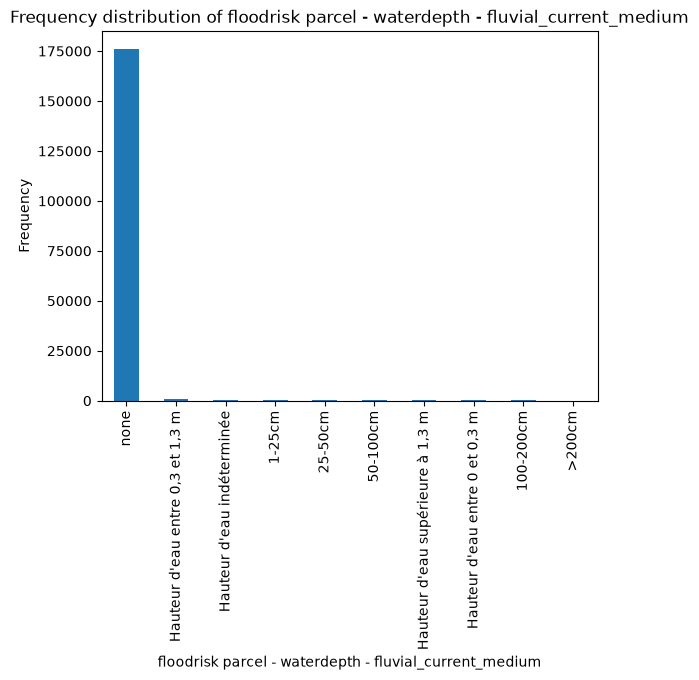

--- floodrisk parcel - waterdepth - fluvial_current_low (10 categories) ---
floodrisk parcel - waterdepth - fluvial_current_low
none                                0.950
Hauteur d'eau indéterminée          0.022
1-25cm                              0.006
50-100cm                            0.006
25-50cm                             0.005
Hauteur d'eau entre 0,3 et 1,3 m    0.004
100-200cm                           0.003
Hauteur d'eau supérieure à 1,3 m    0.003
Hauteur d'eau entre 0 et 0,3 m      0.001
>200cm                              0.001
Name: proportion, dtype: float64


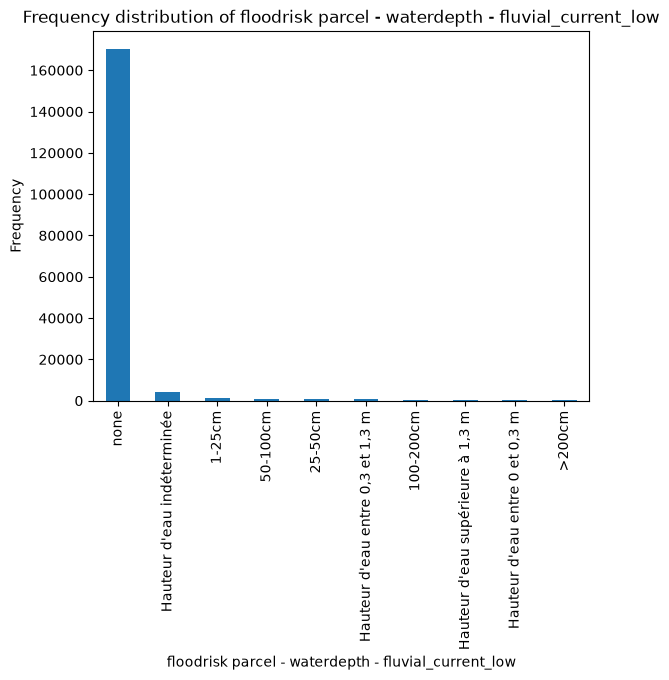

--- floodrisk parcel - waterdepth - pluvial_current_high (9 categories) ---
floodrisk parcel - waterdepth - pluvial_current_high
none                      0.939
1-25cm                    0.021
25-50cm                   0.014
50-100cm                  0.008
Débit de pointe faible    0.008
Débit de pointe moyen     0.007
100-200cm                 0.002
Débit de pointe élevé     0.001
>200cm                    0.000
Name: proportion, dtype: float64


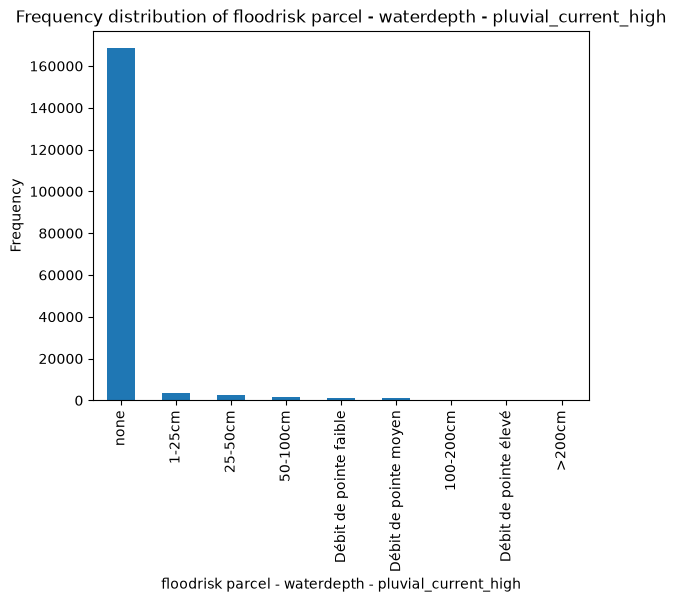

--- floodrisk parcel - waterdepth - pluvial_current_medium (9 categories) ---
floodrisk parcel - waterdepth - pluvial_current_medium
none                      0.891
1-25cm                    0.046
25-50cm                   0.024
50-100cm                  0.014
Débit de pointe moyen     0.010
Débit de pointe faible    0.009
100-200cm                 0.004
Débit de pointe élevé     0.002
>200cm                    0.001
Name: proportion, dtype: float64


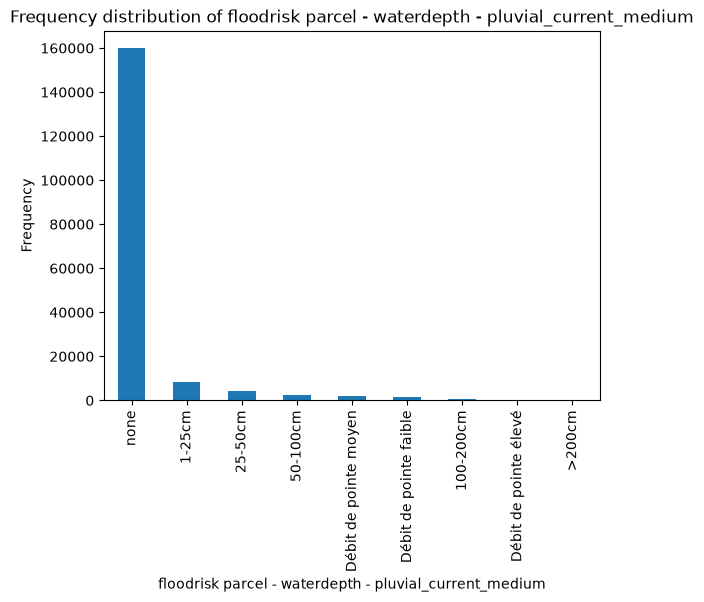

--- floodrisk parcel - waterdepth - pluvial_current_low (9 categories) ---
floodrisk parcel - waterdepth - pluvial_current_low
none                      0.830
1-25cm                    0.077
25-50cm                   0.037
50-100cm                  0.022
Débit de pointe moyen     0.012
Débit de pointe faible    0.011
100-200cm                 0.006
Débit de pointe élevé     0.003
>200cm                    0.002
Name: proportion, dtype: float64


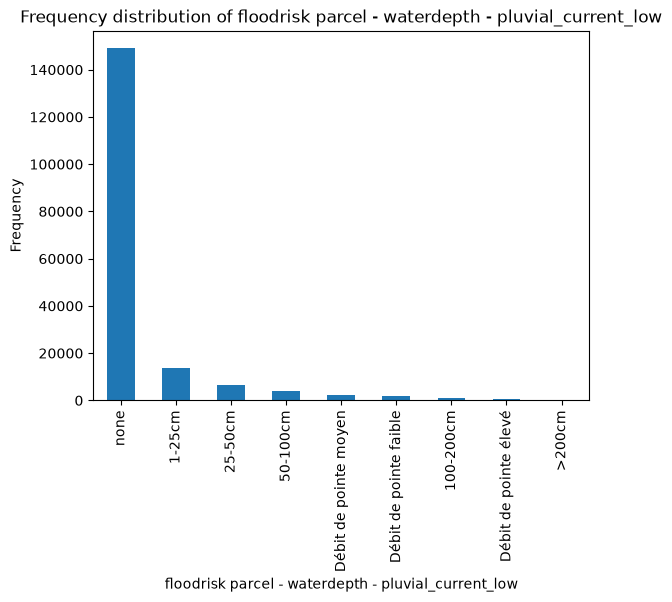

--- floodrisk parcel - waterdepth - coastal_current_medium (6 categories) ---
floodrisk parcel - waterdepth - coastal_current_medium
none         0.994
50-100cm     0.002
100-200cm    0.002
1-25cm       0.001
25-50cm      0.001
>200cm       0.000
Name: proportion, dtype: float64


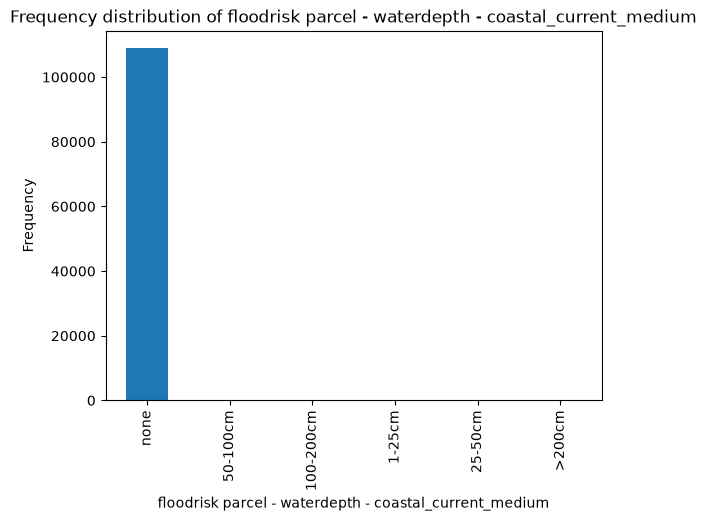

--- floodrisk parcel - waterdepth - coastal_current_low (6 categories) ---
floodrisk parcel - waterdepth - coastal_current_low
none         0.983
1-25cm       0.004
100-200cm    0.004
50-100cm     0.004
25-50cm      0.003
>200cm       0.002
Name: proportion, dtype: float64


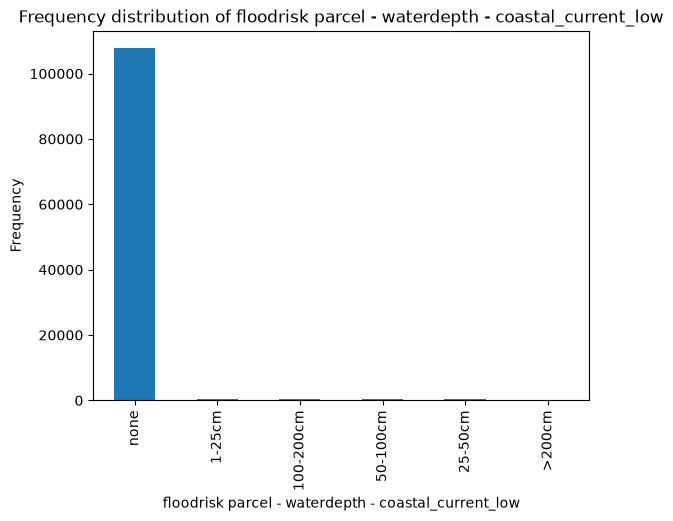

--- floodrisk parcel - waterdepth - fluvial_future_high (6 categories) ---
floodrisk parcel - waterdepth - fluvial_future_high
none         0.992
1-25cm       0.003
25-50cm      0.002
50-100cm     0.002
100-200cm    0.001
>200cm       0.000
Name: proportion, dtype: float64


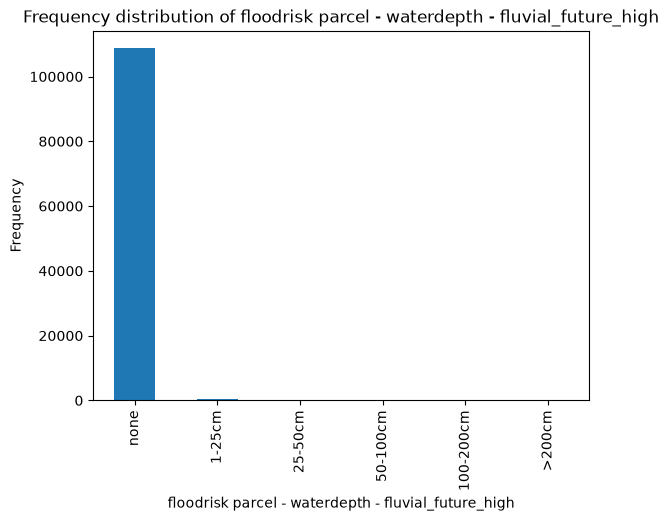

--- floodrisk parcel - waterdepth - fluvial_future_medium (6 categories) ---
floodrisk parcel - waterdepth - fluvial_future_medium
none         0.986
1-25cm       0.004
50-100cm     0.004
25-50cm      0.003
100-200cm    0.002
>200cm       0.000
Name: proportion, dtype: float64


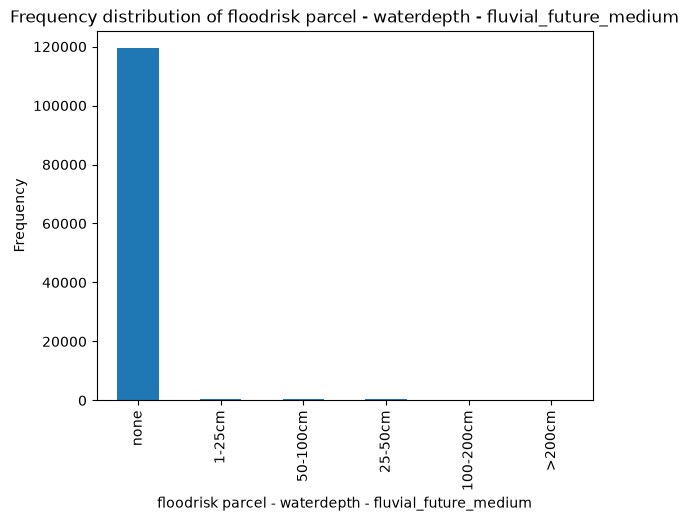

--- floodrisk parcel - waterdepth - fluvial_future_low (6 categories) ---
floodrisk parcel - waterdepth - fluvial_future_low
none         0.967
50-100cm     0.010
1-25cm       0.009
25-50cm      0.007
100-200cm    0.006
>200cm       0.001
Name: proportion, dtype: float64


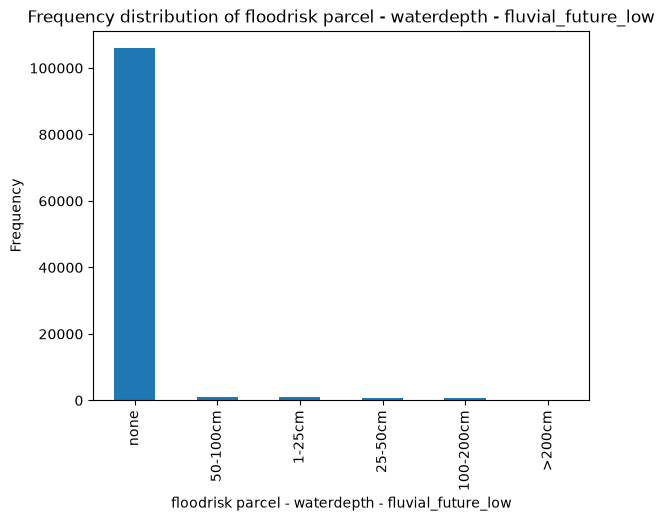

--- floodrisk parcel - waterdepth - pluvial_future_high (6 categories) ---
floodrisk parcel - waterdepth - pluvial_future_high
none         0.879
1-25cm       0.062
25-50cm      0.035
50-100cm     0.019
100-200cm    0.004
>200cm       0.001
Name: proportion, dtype: float64


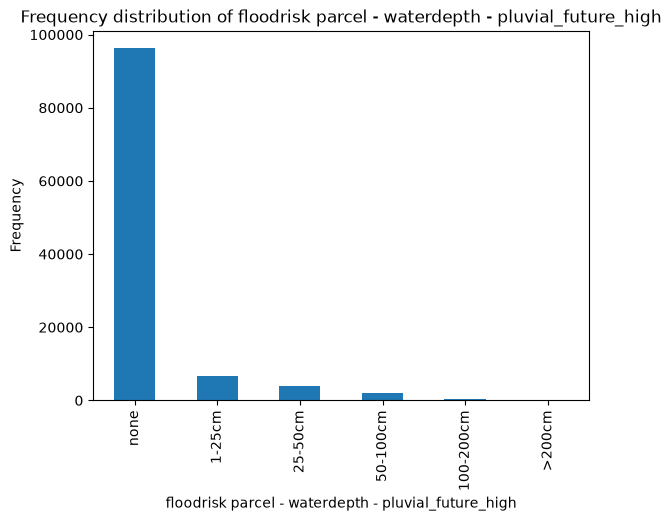

--- floodrisk parcel - waterdepth - pluvial_future_medium (6 categories) ---
floodrisk parcel - waterdepth - pluvial_future_medium
none         0.775
1-25cm       0.125
25-50cm      0.058
50-100cm     0.032
100-200cm    0.009
>200cm       0.002
Name: proportion, dtype: float64


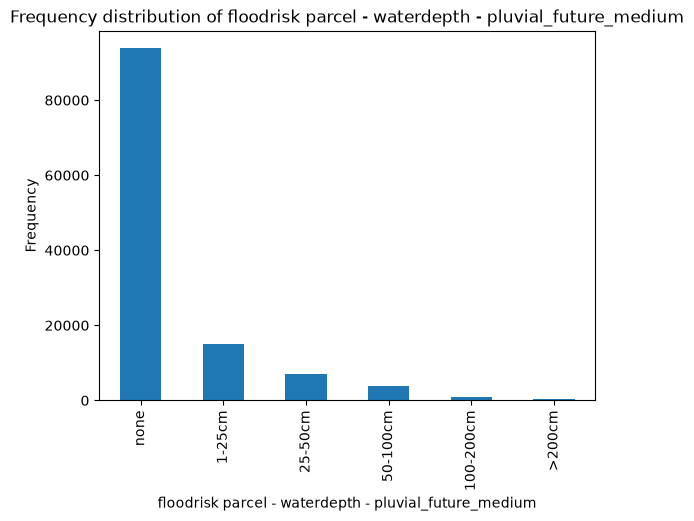

--- floodrisk parcel - waterdepth - pluvial_future_low (6 categories) ---
floodrisk parcel - waterdepth - pluvial_future_low
none         0.632
1-25cm       0.198
25-50cm      0.094
50-100cm     0.055
100-200cm    0.017
>200cm       0.005
Name: proportion, dtype: float64


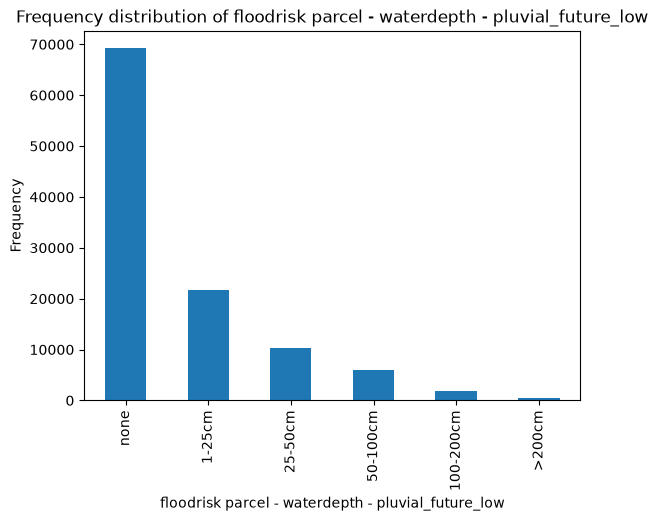

--- floodrisk parcel - waterdepth - coastal_future_medium (6 categories) ---
floodrisk parcel - waterdepth - coastal_future_medium
none         0.988
1-25cm       0.003
100-200cm    0.003
50-100cm     0.003
25-50cm      0.002
>200cm       0.001
Name: proportion, dtype: float64


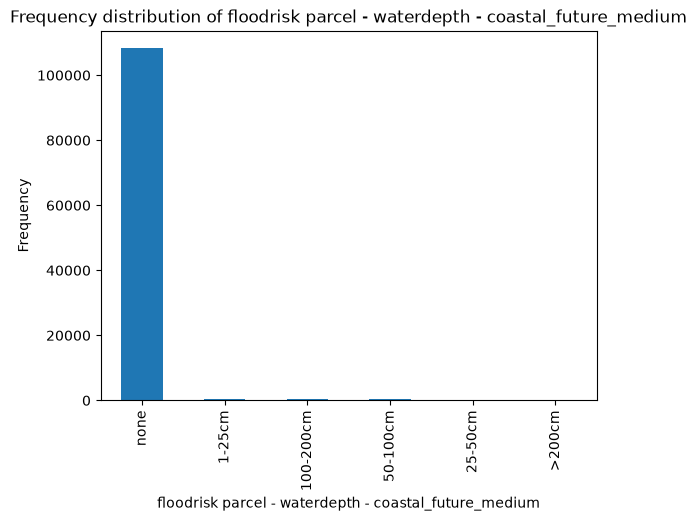

--- floodrisk parcel - waterdepth - coastal_future_low (6 categories) ---
floodrisk parcel - waterdepth - coastal_future_low
none         0.974
50-100cm     0.007
25-50cm      0.006
100-200cm    0.005
1-25cm       0.005
>200cm       0.003
Name: proportion, dtype: float64


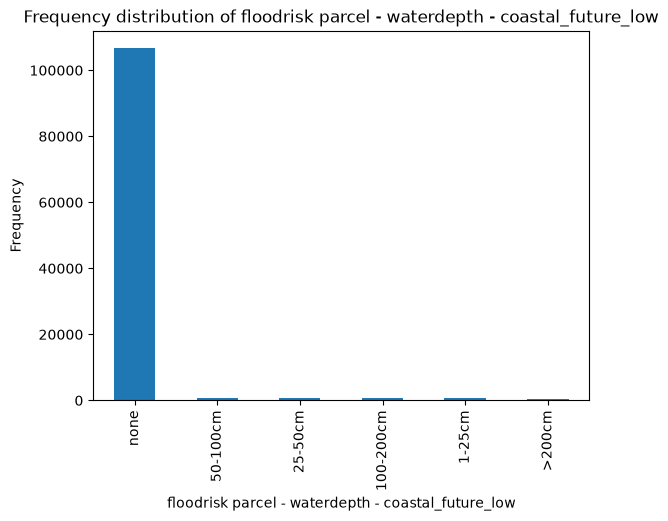

--- floodrisk building - coastal (4 categories) ---
floodrisk building - coastal
none      0.975
medium    0.010
low       0.010
high      0.006
Name: proportion, dtype: float64


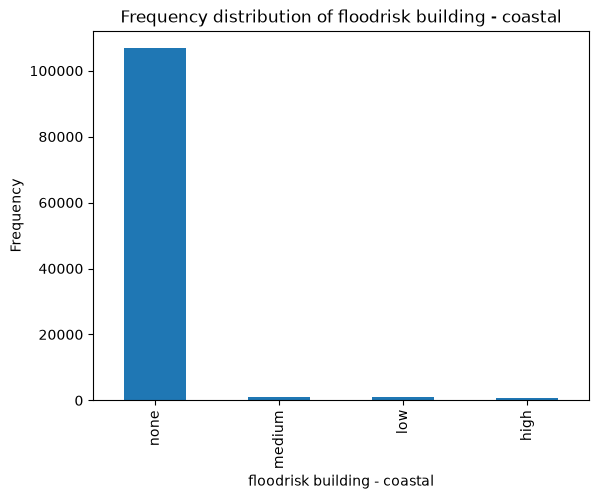

--- floodrisk building - fluvial (4 categories) ---
floodrisk building - fluvial
none      0.963
low       0.018
medium    0.013
high      0.006
Name: proportion, dtype: float64


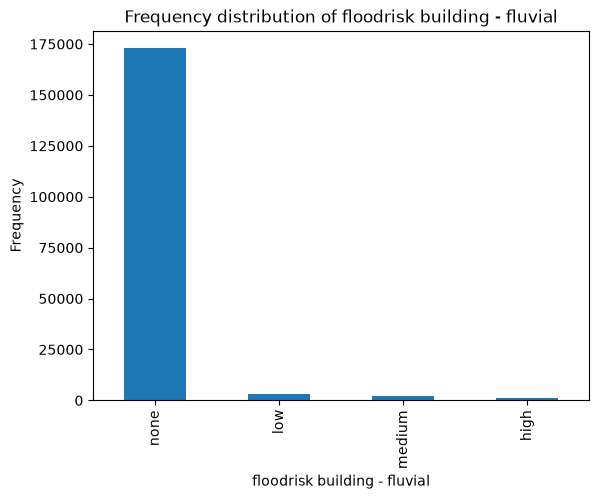

--- floodrisk building - pluvial (4 categories) ---
floodrisk building - pluvial
none      0.866
low       0.059
medium    0.038
high      0.037
Name: proportion, dtype: float64


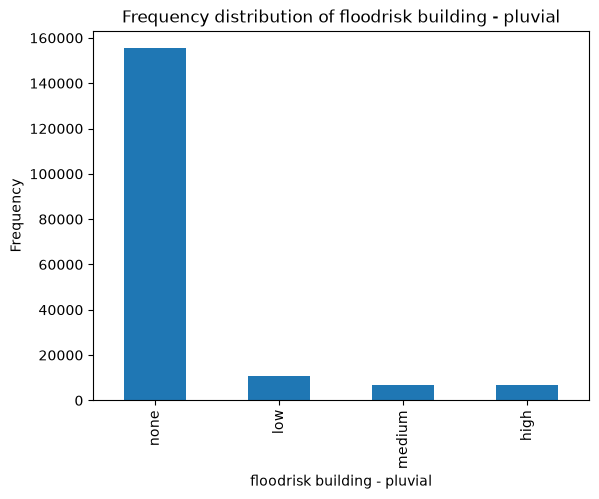

--- floodrisk building - combined (4 categories) ---
floodrisk building - combined
none      0.830
low       0.076
medium    0.050
high      0.044
Name: proportion, dtype: float64


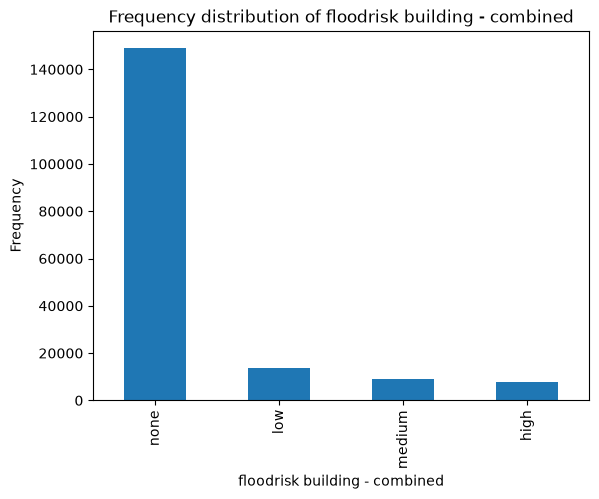

--- floodrisk building - ogoz (1 categories) ---
floodrisk building - ogoz
none    1.0
Name: proportion, dtype: float64


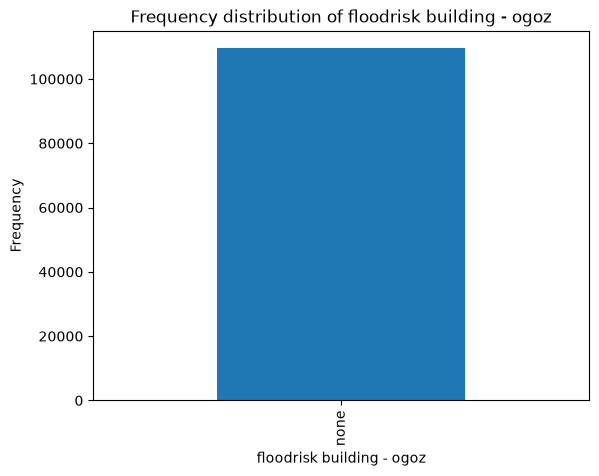

--- floodrisk building - waterdepth - pluvial_current_high (9 categories) ---
floodrisk building - waterdepth - pluvial_current_high
none                      0.982
1-25cm                    0.007
25-50cm                   0.003
Débit de pointe faible    0.003
Débit de pointe moyen     0.003
50-100cm                  0.001
Débit de pointe élevé     0.000
100-200cm                 0.000
>200cm                    0.000
Name: proportion, dtype: float64


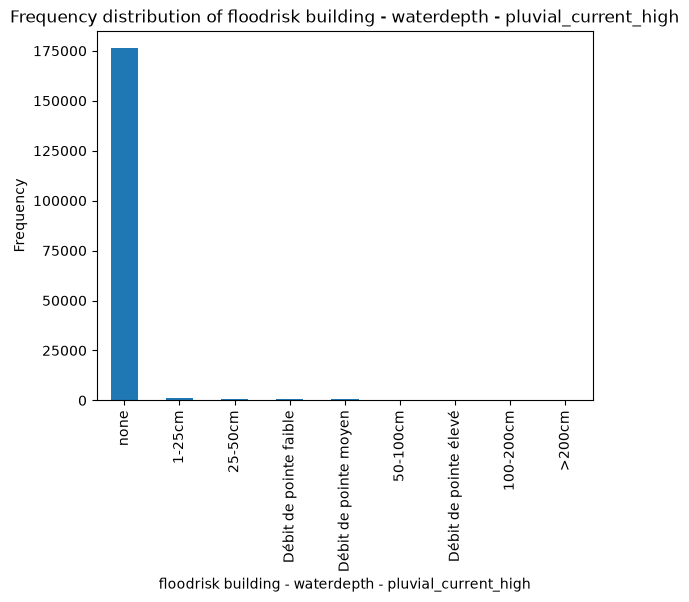

--- floodrisk building - waterdepth - pluvial_current_medium (9 categories) ---
floodrisk building - waterdepth - pluvial_current_medium
none                      0.958
1-25cm                    0.020
25-50cm                   0.010
50-100cm                  0.004
Débit de pointe moyen     0.003
Débit de pointe faible    0.003
100-200cm                 0.001
Débit de pointe élevé     0.001
>200cm                    0.000
Name: proportion, dtype: float64


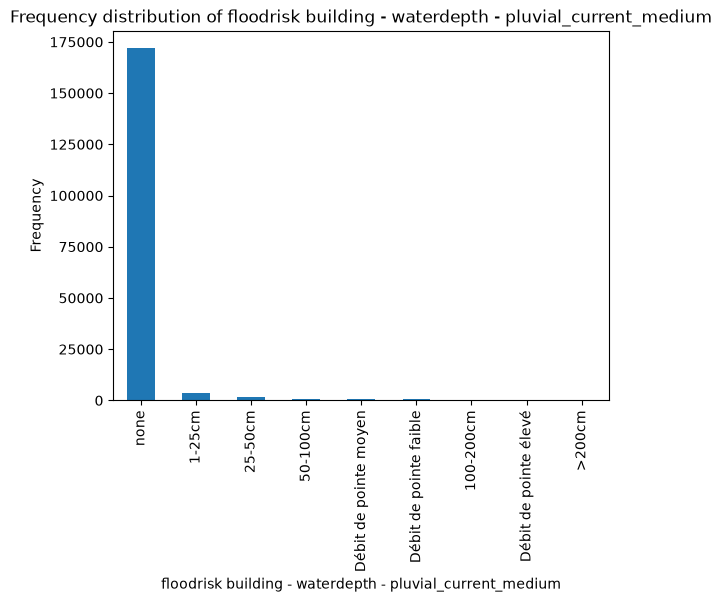

--- floodrisk building - waterdepth - pluvial_current_low (9 categories) ---
floodrisk building - waterdepth - pluvial_current_low
none                      0.925
1-25cm                    0.036
25-50cm                   0.018
50-100cm                  0.008
Débit de pointe moyen     0.004
Débit de pointe faible    0.004
100-200cm                 0.002
Débit de pointe élevé     0.001
>200cm                    0.001
Name: proportion, dtype: float64


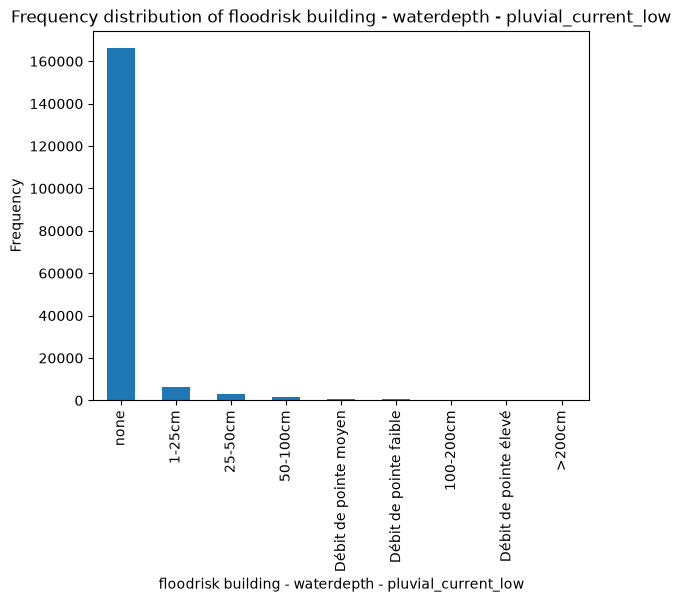

--- floodrisk building - waterdepth - pluvial_future_high (6 categories) ---
floodrisk building - waterdepth - pluvial_future_high
none         0.963
1-25cm       0.023
25-50cm      0.010
50-100cm     0.003
100-200cm    0.001
>200cm       0.000
Name: proportion, dtype: float64


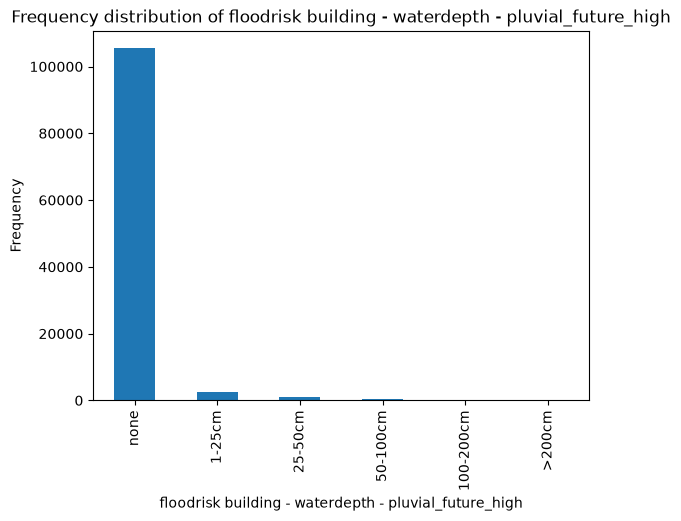

--- floodrisk building - waterdepth - pluvial_future_medium (6 categories) ---
floodrisk building - waterdepth - pluvial_future_medium
none         0.908
1-25cm       0.054
25-50cm      0.024
50-100cm     0.010
100-200cm    0.003
>200cm       0.001
Name: proportion, dtype: float64


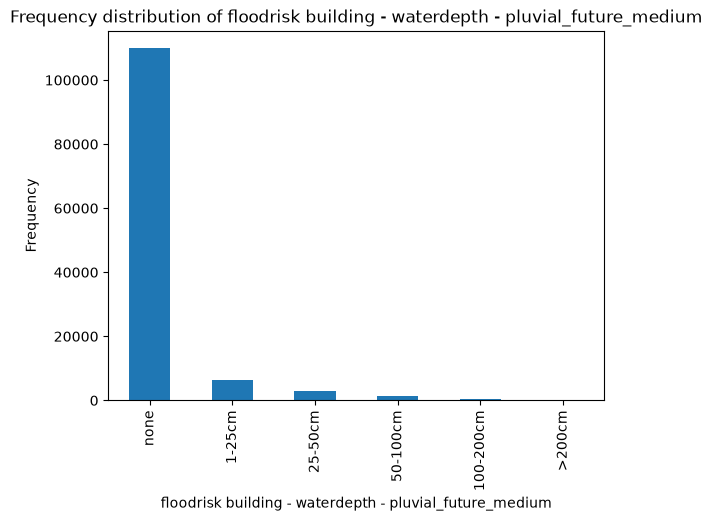

--- floodrisk building - waterdepth - pluvial_future_low (6 categories) ---
floodrisk building - waterdepth - pluvial_future_low
none         0.816
1-25cm       0.100
25-50cm      0.050
50-100cm     0.024
100-200cm    0.008
>200cm       0.002
Name: proportion, dtype: float64


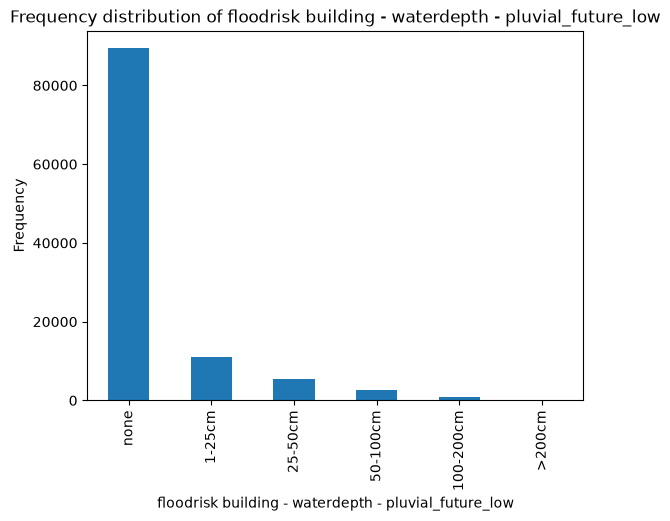

--- floodrisk building - waterdepth - fluvial_current_high (10 categories) ---
floodrisk building - waterdepth - fluvial_current_high
none                                0.995
Hauteur d'eau entre 0,3 et 1,3 m    0.002
Hauteur d'eau entre 0 et 0,3 m      0.001
Hauteur d'eau supérieure à 1,3 m    0.000
1-25cm                              0.000
Hauteur d'eau indéterminée          0.000
25-50cm                             0.000
50-100cm                            0.000
100-200cm                           0.000
>200cm                              0.000
Name: proportion, dtype: float64


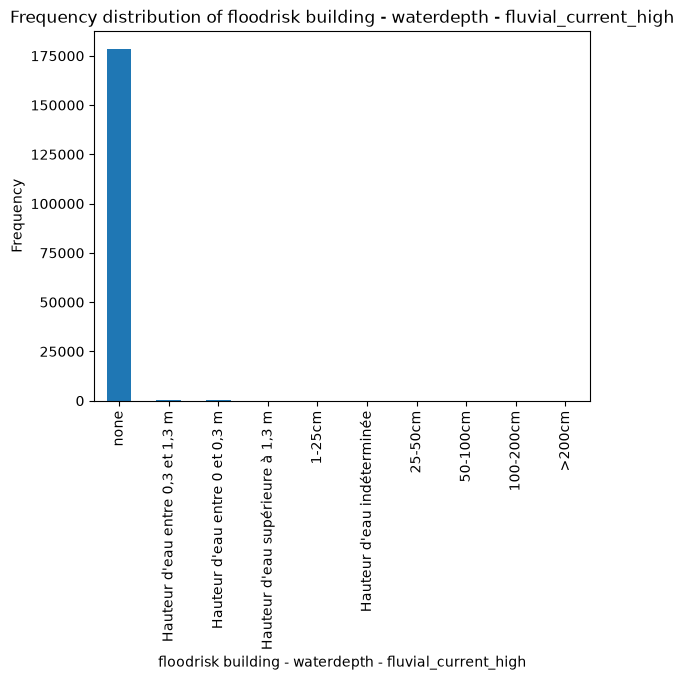

--- floodrisk building - waterdepth - fluvial_current_medium (10 categories) ---
floodrisk building - waterdepth - fluvial_current_medium
none                                0.991
Hauteur d'eau entre 0,3 et 1,3 m    0.003
Hauteur d'eau indéterminée          0.002
1-25cm                              0.001
Hauteur d'eau entre 0 et 0,3 m      0.001
Hauteur d'eau supérieure à 1,3 m    0.001
25-50cm                             0.001
50-100cm                            0.000
100-200cm                           0.000
>200cm                              0.000
Name: proportion, dtype: float64


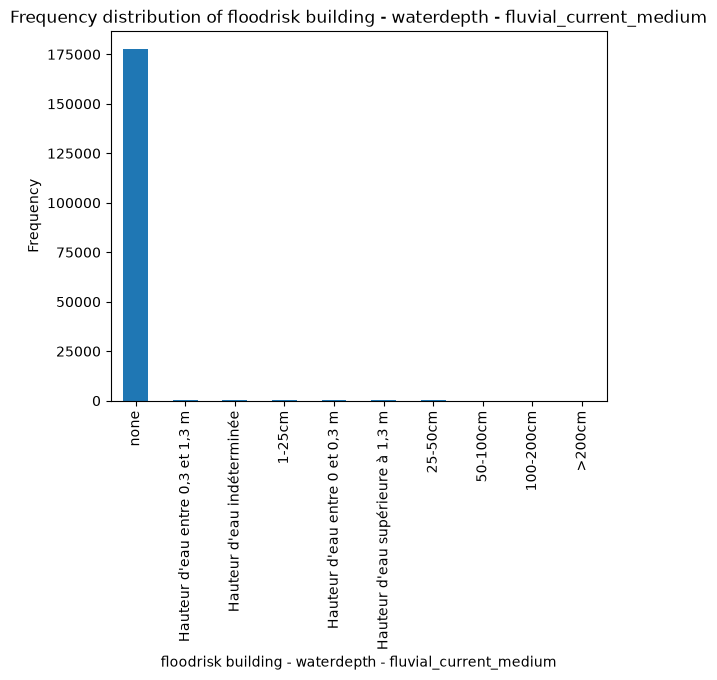

--- floodrisk building - waterdepth - fluvial_current_low (10 categories) ---
floodrisk building - waterdepth - fluvial_current_low
none                                0.968
Hauteur d'eau indéterminée          0.015
1-25cm                              0.004
Hauteur d'eau entre 0,3 et 1,3 m    0.003
50-100cm                            0.003
25-50cm                             0.003
100-200cm                           0.001
Hauteur d'eau entre 0 et 0,3 m      0.001
Hauteur d'eau supérieure à 1,3 m    0.001
>200cm                              0.000
Name: proportion, dtype: float64


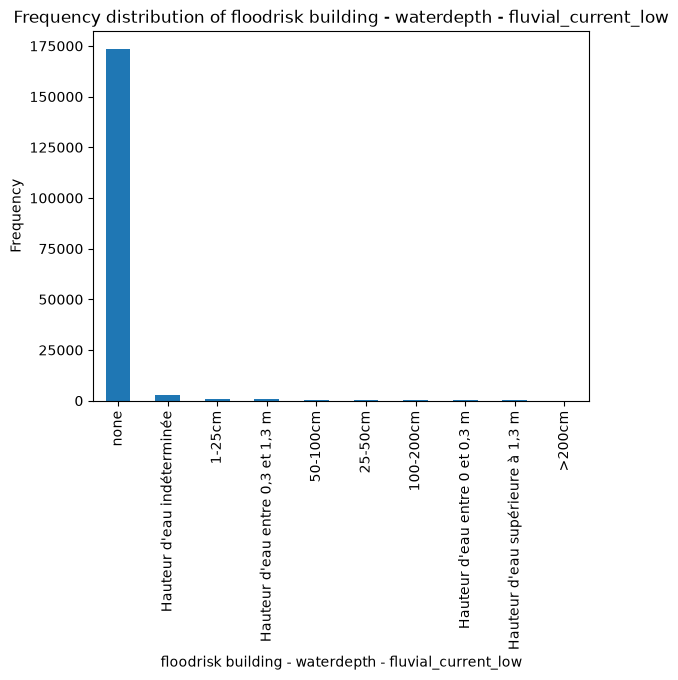

--- floodrisk building - waterdepth - coastal_current_medium (6 categories) ---
floodrisk building - waterdepth - coastal_current_medium
none         0.994
50-100cm     0.002
100-200cm    0.002
1-25cm       0.001
25-50cm      0.001
>200cm       0.000
Name: proportion, dtype: float64


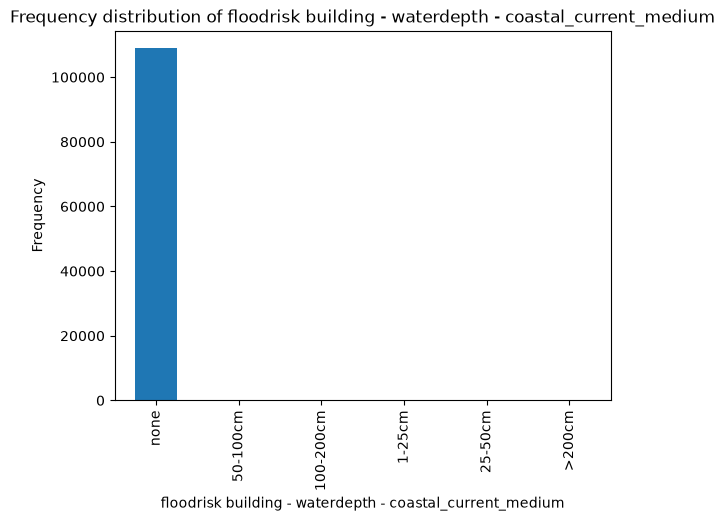

--- floodrisk building - waterdepth - coastal_current_low (6 categories) ---
floodrisk building - waterdepth - coastal_current_low
none         0.984
1-25cm       0.004
100-200cm    0.004
50-100cm     0.003
25-50cm      0.003
>200cm       0.001
Name: proportion, dtype: float64


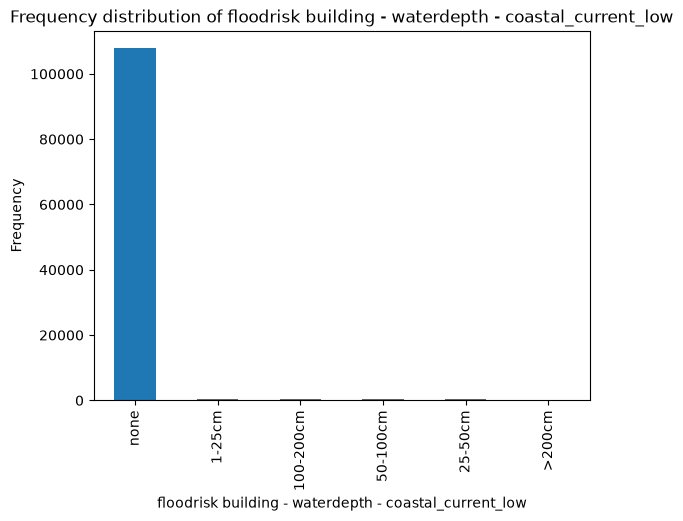

--- floodrisk building - waterdepth - fluvial_future_high (6 categories) ---
floodrisk building - waterdepth - fluvial_future_high
none         0.998
1-25cm       0.001
25-50cm      0.001
50-100cm     0.000
100-200cm    0.000
>200cm       0.000
Name: proportion, dtype: float64


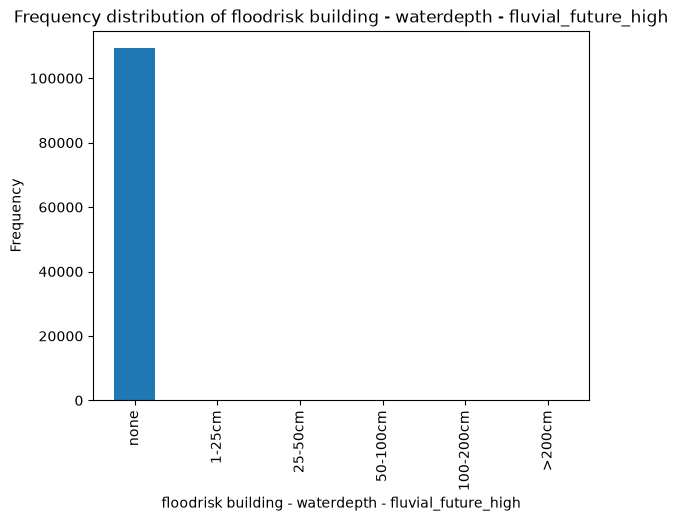

--- floodrisk building - waterdepth - fluvial_future_medium (6 categories) ---
floodrisk building - waterdepth - fluvial_future_medium
none         0.993
1-25cm       0.002
50-100cm     0.002
25-50cm      0.002
100-200cm    0.001
>200cm       0.000
Name: proportion, dtype: float64


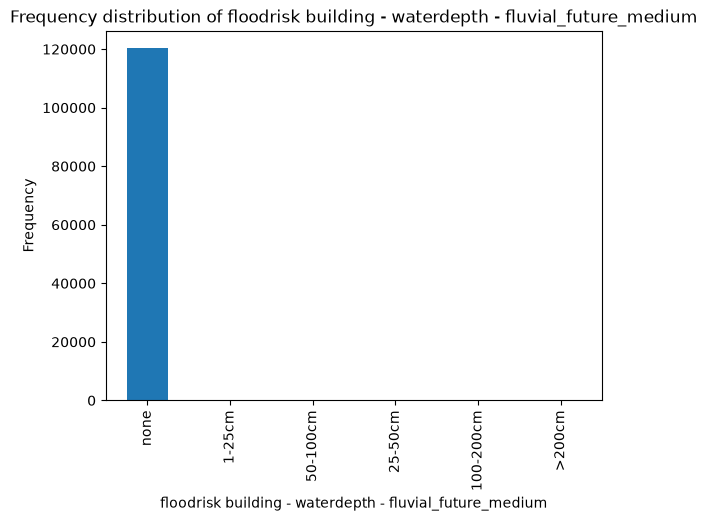

--- floodrisk building - waterdepth - fluvial_future_low (6 categories) ---
floodrisk building - waterdepth - fluvial_future_low
none         0.977
50-100cm     0.007
1-25cm       0.007
25-50cm      0.006
100-200cm    0.003
>200cm       0.000
Name: proportion, dtype: float64


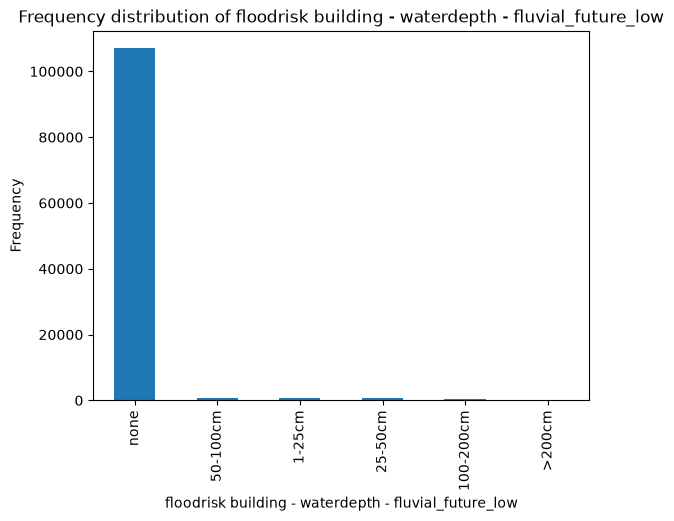

--- floodrisk building - waterdepth - coastal_future_medium (6 categories) ---
floodrisk building - waterdepth - coastal_future_medium
none         0.989
1-25cm       0.003
100-200cm    0.003
50-100cm     0.003
25-50cm      0.002
>200cm       0.001
Name: proportion, dtype: float64


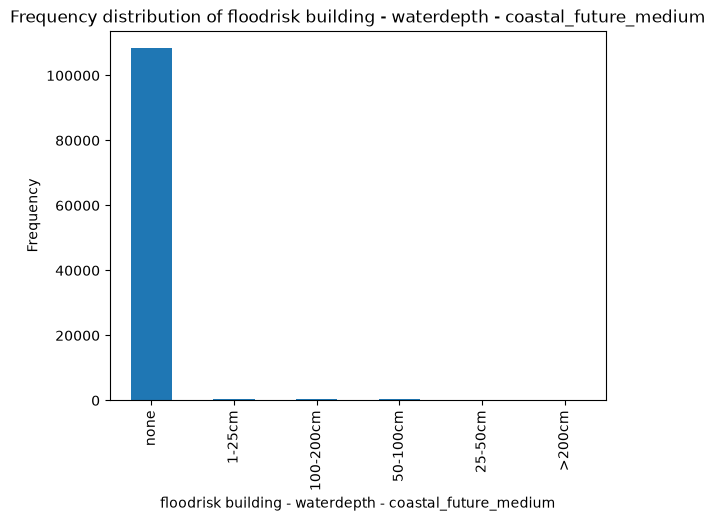

--- floodrisk building - waterdepth - coastal_future_low (6 categories) ---
floodrisk building - waterdepth - coastal_future_low
none         0.974
50-100cm     0.007
25-50cm      0.006
1-25cm       0.005
100-200cm    0.005
>200cm       0.003
Name: proportion, dtype: float64


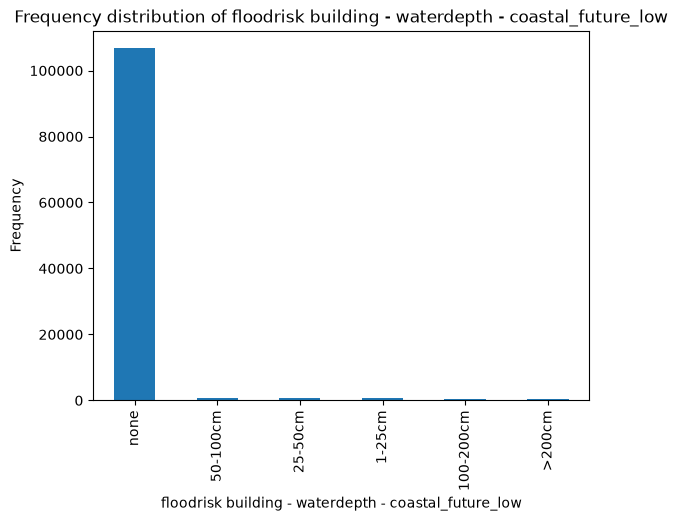

--- main building selection (2 categories) ---
main building selection
address on building       0.986
mainBuilding on parcel    0.014
Name: proportion, dtype: float64


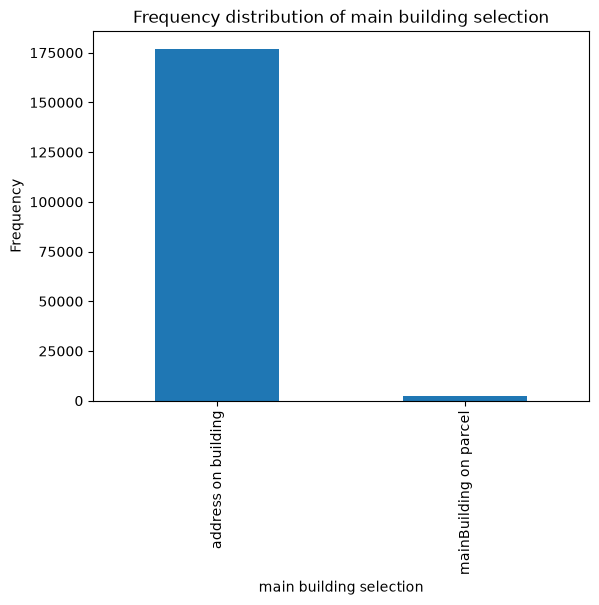

--- main building has multiple units (2 categories) ---
main building has multiple units
no     0.738
yes    0.262
Name: proportion, dtype: float64


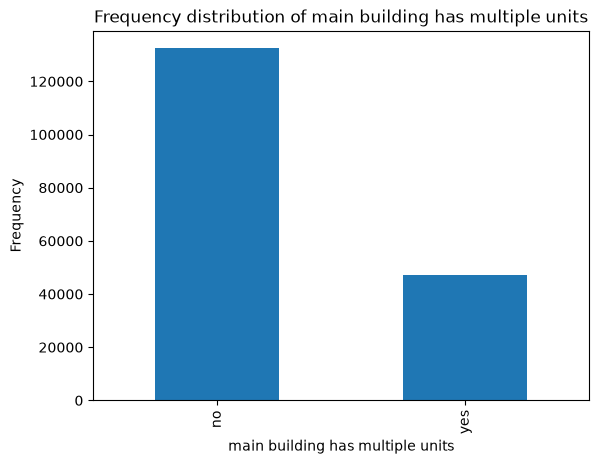

--- part of whole building (2 categories) ---
part of whole building
whole building            0.761
1 unit out of building    0.239
Name: proportion, dtype: float64


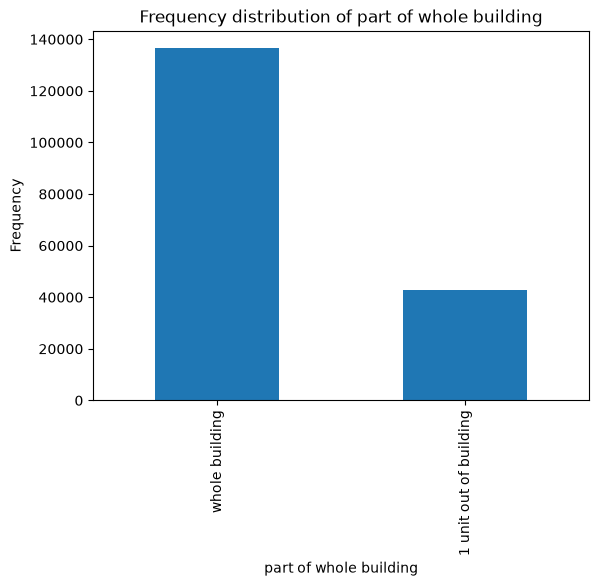

--- part of whole building (source) (9 categories) ---
part of whole building (source)
businfo / dossierInfo                      0.661
pandtype                                   0.129
busnumber & pandtype                       0.056
1 address & pricePerUnit < P50             0.045
1 address & price < P25                    0.033
busnumber                                  0.031
multiple addresses & pricePerUnit < P25    0.022
multiple addresses & price < P75           0.015
multiple addresses & pricePerUnit < P50    0.007
Name: proportion, dtype: float64


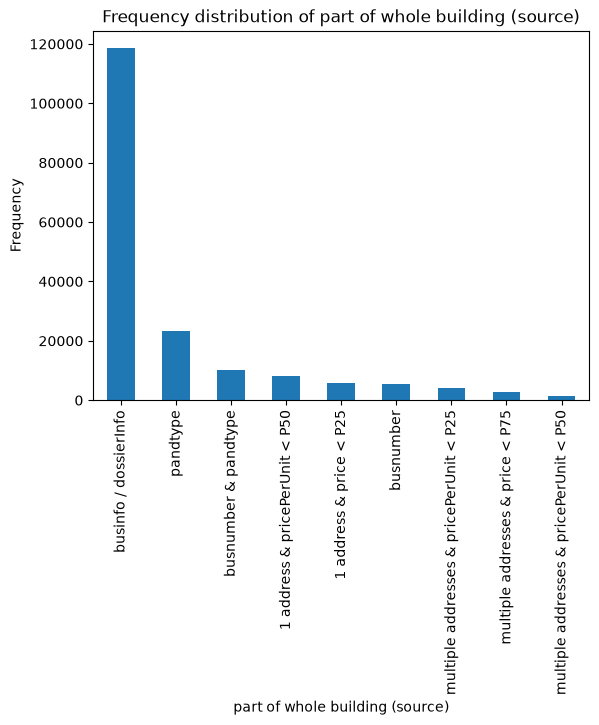

--- destination (4 categories) ---
destination
residential                      0.839
non-residential                  0.079
residential / non-residential    0.065
mixed use                        0.017
Name: proportion, dtype: float64


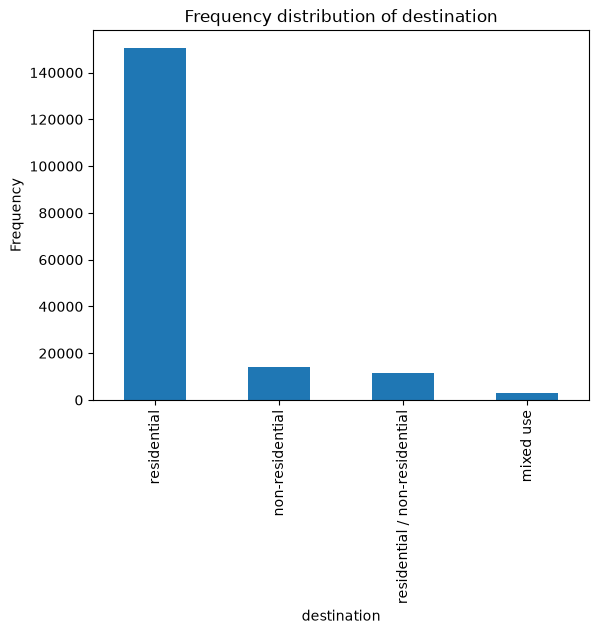

--- detailed destination (995 categories) ---
detailed destination
single-family home         0.614
apartment                  0.166
apartment block            0.063
retail                     0.025
industrial                 0.022
apartment / retail         0.016
healthcare                 0.009
apartment / healthcare     0.006
apartment block, retail    0.005
office                     0.004
Name: proportion, dtype: float64
--- source of builtyear (3 categories) ---
source of builtyear
image analysis             0.777
regional topo reference    0.183
building permit            0.039
Name: proportion, dtype: float64


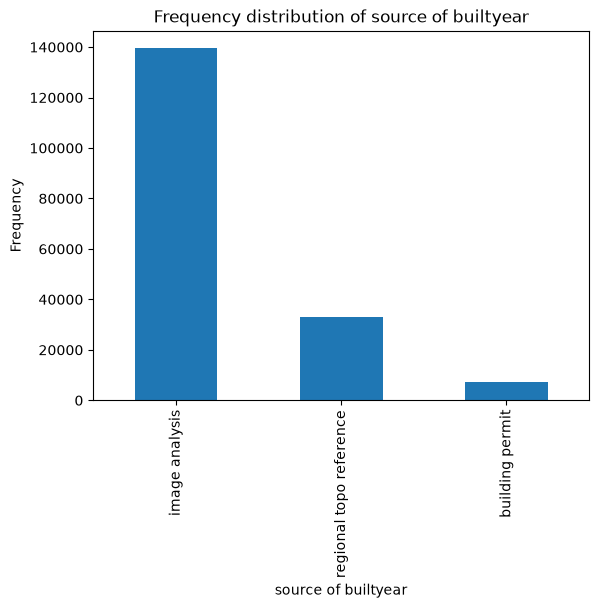

--- building type (10 categories) ---
building type
freeStandingHouse    0.329
terracedHouse        0.263
semiAttachedHouse    0.234
building             0.153
industrial           0.017
annex                0.003
school               0.001
public               0.001
health               0.000
sport                0.000
Name: proportion, dtype: float64


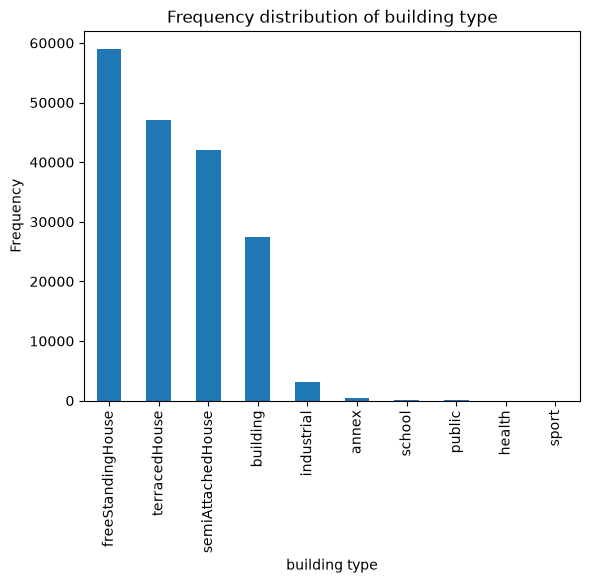

--- rooftype (4 categories) ---
rooftype
inclined    0.463
mixed       0.403
flat        0.134
non-flat    0.000
Name: proportion, dtype: float64


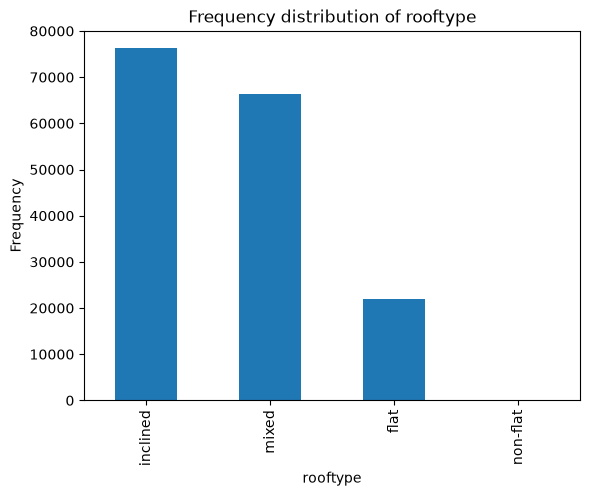

--- solarpanels (2 categories) ---
solarpanels
no     0.71
yes    0.29
Name: proportion, dtype: float64


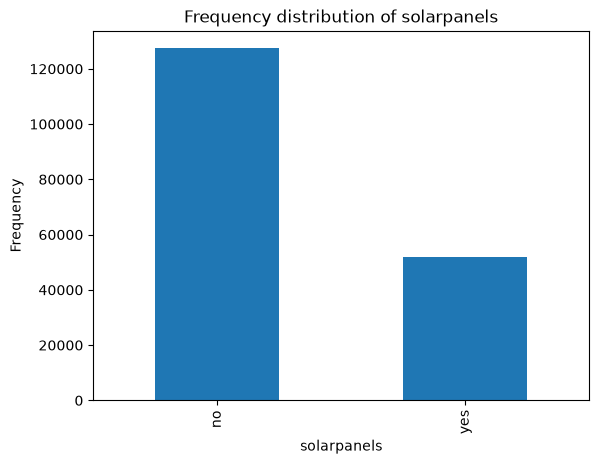

--- patrimony (2 categories) ---
patrimony
no     0.922
yes    0.078
Name: proportion, dtype: float64


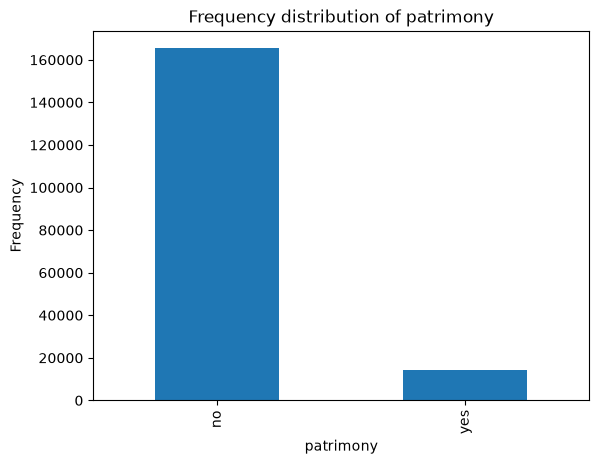

--- patrimony code (109 categories) ---
patrimony code
vastgestelde archeologische zone                                                                                  0.254
vastgesteld bouwkundig erfgoed                                                                                    0.234
inventaris bouwkundig erfgoed                                                                                     0.148
monument protégé                                                                                                  0.083
vastgestelde archeologische zone; vastgesteld bouwkundig erfgoed                                                  0.054
beschermd stads- of dorpsgezicht, intrinsiek; vastgesteld bouwkundig erfgoed                                      0.030
beschermd monument                                                                                                0.027
monument (pastillé)                                                                                      

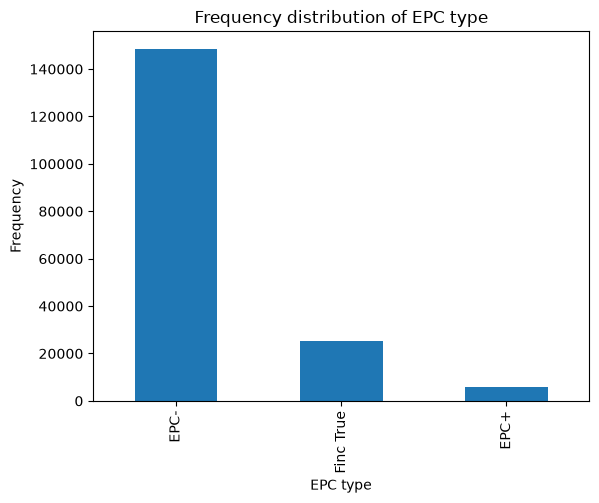

--- region (3 categories) ---
region
Flanders    0.610
Wallonia    0.325
Brussels    0.064
Name: proportion, dtype: float64


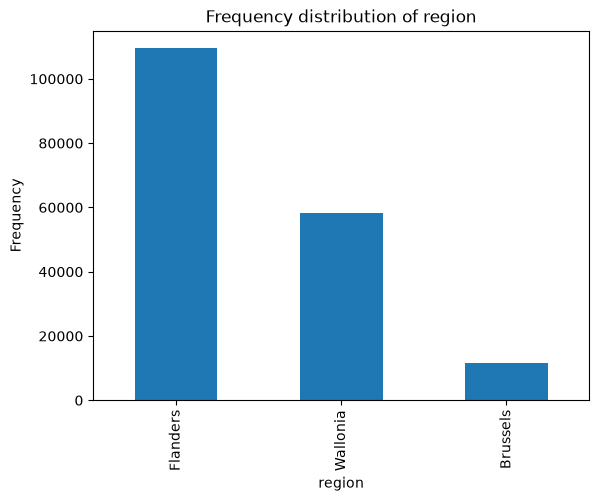

In [7]:
for var in categorical_vars:
    n_unique = data[var].nunique()
    print(f"--- {var} ({n_unique} categories) ---")
    print(data[var].value_counts(normalize=True).head(10).round(3))
    if n_unique <= 20:                     # only plot when the chart is readable
        data[var].value_counts().plot(kind="bar")
        plt.title(f"Frequency distribution of {var}"); plt.ylabel("Frequency")
        plt.show()

## Step 3 · Continuous variables: summary table and key plots

In [8]:
continuous_vars = data.select_dtypes(include="number").columns
data[continuous_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
REAL_ESTATE_TYP,172675.0,1.046818e+02,4.406715e+01,100.000000,1.000000e+02,1.000000e+02,1.000000e+02,6.110000e+02
Price,170138.0,4.057495e+05,3.319042e+05,0.000000,2.601558e+05,3.647077e+05,4.921271e+05,9.000000e+07
matched_postalcode,179446.0,5.372642e+03,2.939099e+03,1000.000000,2.620000e+03,4.970000e+03,8.510000e+03,9.992000e+03
fed_address_id,175361.0,3.095853e+10,5.628138e+10,10003.000000,3.000146e+09,2.000141e+10,2.000365e+10,2.000315e+11
x_ll,179446.0,4.368660e+00,8.153740e-01,2.566510,3.767159e+00,4.391704e+00,4.904499e+00,6.353676e+00
y_ll,179446.0,5.083406e+01,3.465236e-01,49.507004,5.063983e+01,5.087565e+01,5.109334e+01,5.150375e+01
average net income (municipality),179446.0,3.681173e+04,5.188901e+03,22081.170000,3.394688e+04,3.668979e+04,3.990614e+04,5.849001e+04
average total taxes (municipality),179446.0,9.492737e+03,2.440988e+03,3110.340000,7.834360e+03,9.374760e+03,1.079358e+04,1.907246e+04
average cars per household,179446.0,1.113891e+00,2.347682e-01,0.330000,1.010000e+00,1.170000e+00,1.280000e+00,1.680000e+00
maxSpeed,179446.0,4.558416e+01,1.164267e+01,5.000000,3.000000e+01,5.000000e+01,5.000000e+01,1.200000e+02


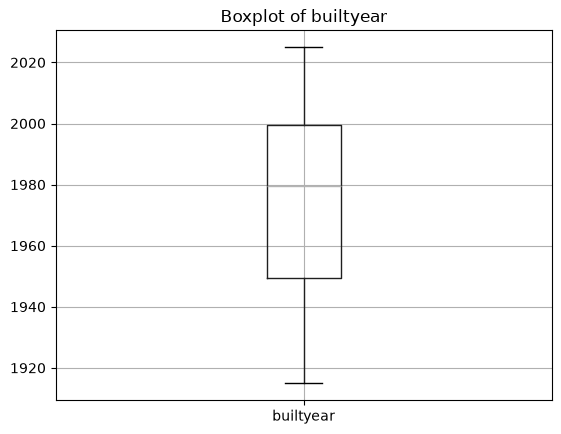

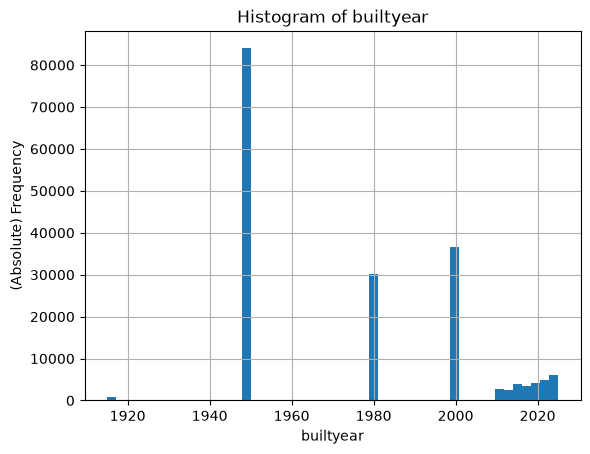

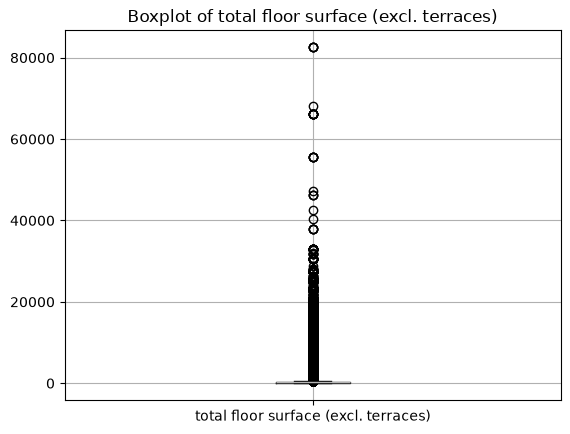

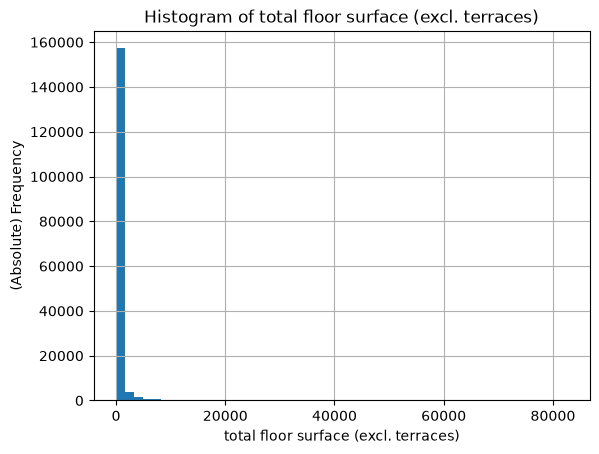

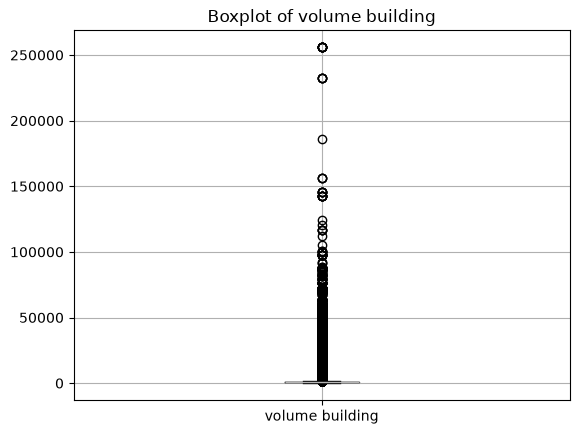

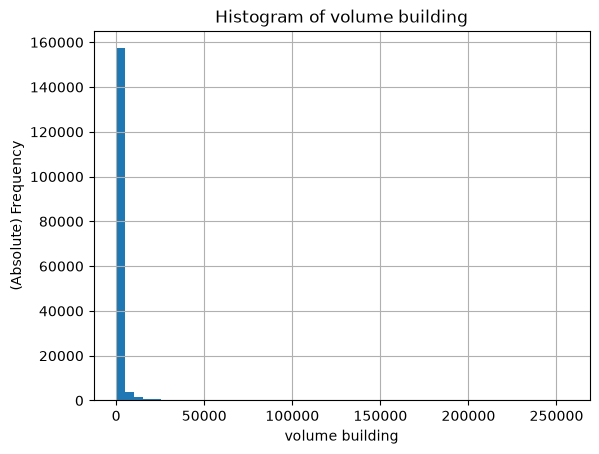

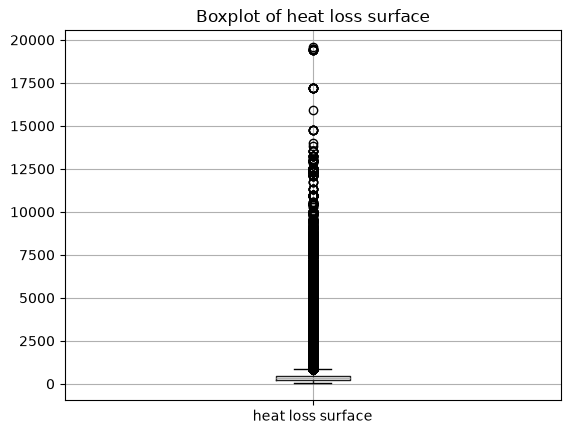

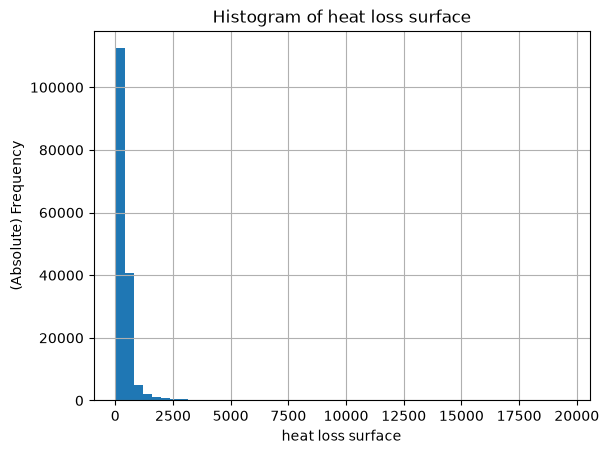

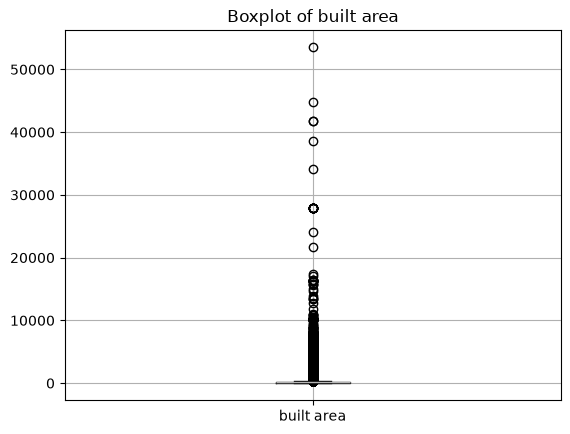

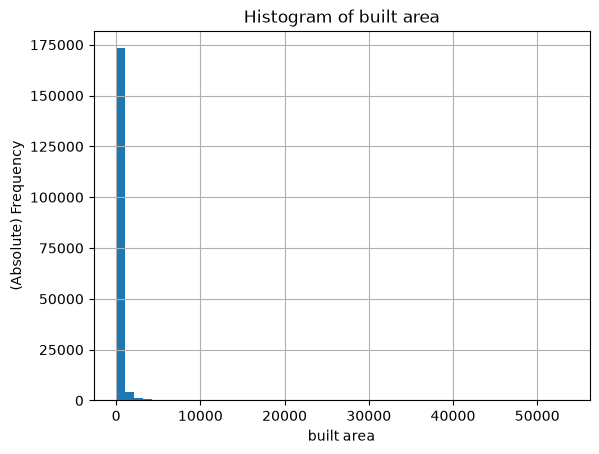

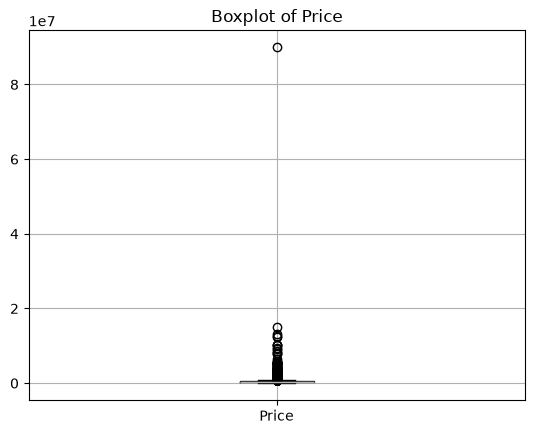

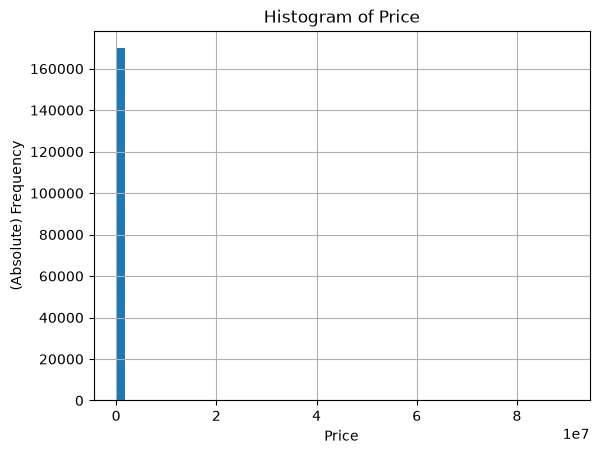

In [9]:
key_vars = ["builtyear", "total floor surface (excl. terraces)", "volume building",
            "heat loss surface", "built area", "Price"]

for var in key_vars:
    data.boxplot(column=[var])
    plt.title(f"Boxplot of {var}"); plt.show()

    data[var].hist(bins=50)
    plt.title(f"Histogram of {var}"); plt.xlabel(var); plt.ylabel("(Absolute) Frequency")
    plt.show()

## Step 4 · Univariate statistics

In [10]:
var = "builtyear"
print("mean:  ", data[var].mean())
print("std:   ", data[var].std())
print("min:   ", data[var].min())
print("max:   ", data[var].max())
print("median:", data[var].median())
print("Q1:    ", data[var].quantile(0.25))      # .quantile() ignores NaN, np.percentile does not
print("Q3:    ", data[var].quantile(0.75))

mean:   1975.2934977653445
std:    27.253797023857604
min:    1915.0
max:    2025.0
median: 1979.5
Q1:     1949.5
Q3:     1999.5


## Step 5 · Missing values

In [11]:
def percentage_missing(df, var):
    return df[var].isna().sum() / len(df[var]) * 100

missing = pd.Series({var: percentage_missing(data, var) for var in data.columns})
missing = missing[missing > 0].sort_values(ascending=False)
print(f"{len(missing)} columns have missing values")
print(missing.round(1).to_string())

40 columns have missing values
swimming pool surface                                       96.7
patrimony code                                              92.2
habitable surface (apartment)                               78.5
floodrisk parcel - waterdepth - fluvial_future_high         39.0
floodrisk parcel - waterdepth - coastal_future_low          39.0
floodrisk parcel - waterdepth - coastal_future_medium       39.0
floodrisk parcel - waterdepth - pluvial_future_low          39.0
floodrisk parcel - waterdepth - pluvial_future_high         39.0
floodrisk parcel - waterdepth - fluvial_future_low          39.0
floodrisk parcel - waterdepth - coastal_current_low         39.0
floodrisk parcel - waterdepth - coastal_current_medium      39.0
floodrisk building - ogoz                                   39.0
floodrisk building - waterdepth - coastal_current_low       39.0
floodrisk building - waterdepth - fluvial_future_high       39.0
floodrisk building - waterdepth - coastal_current_medium   

**Why values are missing.** Most missingness has a reason:
- flood columns (39% missing) only exist for Flanders,
- garden surface is missing when there is no garden,
- one block of rows misses all 3D building data together.

In [12]:
flood_missing = data["floodrisk parcel - coastal"].isna()
print(pd.crosstab(data["region"], flood_missing, normalize="index").round(2))

floodrisk parcel - coastal  False  True 
region                                  
Brussels                      0.0    1.0
Flanders                      1.0    0.0
Wallonia                      0.0    1.0


In [13]:
print(pd.crosstab(data["garden presence"], data["garden surface"].isna()))

garden surface    False  True 
garden presence               
no                    0  15584
yes              163862      0


In [14]:
cols_3d = ["volume building", "floors (above ground)", "total floor surface (excl. terraces)",
           "heat loss surface", "formfactor_3D", "rooftype"]
print("rows missing ALL 3D columns:", data[cols_3d].isna().all(axis=1).sum())
print("rows missing ANY 3D column: ", data[cols_3d].isna().any(axis=1).sum())

rows missing ALL 3D columns: 14739
rows missing ANY 3D column:  14739


## Step 6 · Target vs. variables (multivariate)

In [15]:
for var in ["building type", "rooftype", "solarpanels", "region", "EPC type"]:
    print(f"--- {var} ---")
    print(pd.crosstab(data[var], status, normalize="index")[ORDER].round(2))

--- building type ---
EPC label            A+     A     B     C     D     E     F     G
building type                                                    
annex              0.10  0.32  0.19  0.10  0.08  0.05  0.12  0.03
building           0.00  0.12  0.29  0.20  0.15  0.10  0.07  0.07
freeStandingHouse  0.01  0.06  0.15  0.23  0.16  0.10  0.21  0.07
health             0.00  0.10  0.33  0.33  0.05  0.10  0.10  0.00
industrial         0.01  0.14  0.16  0.21  0.18  0.10  0.16  0.04
public             0.01  0.14  0.21  0.34  0.15  0.05  0.09  0.02
school             0.02  0.09  0.21  0.14  0.17  0.13  0.13  0.11
semiAttachedHouse  0.01  0.08  0.14  0.16  0.15  0.12  0.28  0.07
sport              0.05  0.10  0.14  0.24  0.14  0.05  0.14  0.14
terracedHouse      0.00  0.04  0.09  0.19  0.27  0.21  0.15  0.05
--- rooftype ---
EPC label    A+     A     B     C     D     E     F     G
rooftype                                                 
flat       0.00  0.10  0.26  0.20  0.17  0.10  0.12  

In [16]:
# Build period vs. label: share of each label per period
period = pd.cut(data["builtyear"], [0, 1930, 1970, 1990, 2010, 2030],
                labels=["<1930", "1930-1969", "1970-1989", "1990-2009", "2010+"], right=False)
print(pd.crosstab(period, status, normalize="index")[ORDER].round(2))

print(data.assign(label=status).groupby("label")[["builtyear", "heat loss surface", "formfactor_3D"]]
      .median().reindex(ORDER).round(1))

EPC label    A+     A     B     C     D     E     F     G
builtyear                                                
<1930      0.00  0.00  0.01  0.07  0.17  0.22  0.22  0.31
1930-1969  0.00  0.01  0.06  0.13  0.21  0.17  0.30  0.11
1970-1989  0.00  0.01  0.06  0.22  0.21  0.23  0.23  0.05
1990-2009  0.00  0.01  0.22  0.44  0.22  0.06  0.04  0.02
2010+      0.05  0.41  0.47  0.06  0.01  0.00  0.01  0.00
       builtyear  heat loss surface  formfactor_3D
label                                             
A+        2023.0              391.8            0.6
A         2022.0              367.0            0.6
B         1999.5              409.4            0.6
C         1979.5              369.8            0.5
D         1949.5              305.0            0.4
E         1949.5              284.6            0.5
F         1949.5              325.9            0.5
G         1949.5              314.9            0.4


## Step 7 · Does the scoring file look like the training file?

In [17]:
score = fix_types(raw_score)
compare = pd.DataFrame({
    "train": [data["builtyear_is_range"].mean(), (data["region"] == "Flanders").mean(),
              data["EPC type"].eq("EPC-").mean(), data["Price"].median()],
    "scoring": [score["builtyear_is_range"].mean(), (score["region"] == "Flanders").mean(),
                score["EPC type"].eq("EPC-").mean(), score["Price"].median()]},
    index=["share build year only as period", "share Flanders", "share EPC-", "median price"])
compare.round(3)

,train,scoring
share build year only as period,0.844,0.843
share Flanders,0.610,0.614
share EPC-,0.828,0.827
median price,364707.700,365000.000


## SUMMARY ALL OBSERVATIONS:

In [18]:
# ---------- Collect all data-understanding results in one Excel file ----------
cat_vars = data.select_dtypes(exclude="number").columns
num_vars = data.select_dtypes(include="number").columns
is_range = data["builtyear_is_range"].astype(bool)

overview = pd.DataFrame({"value": {
    "training rows": len(data),
    "scoring rows": len(raw_score),
    "features (after type fixes)": data.shape[1],
    "categorical features": len(cat_vars),
    "numeric features": len(num_vars),
    "columns with missing values": int((data.isna().mean() > 0).sum()),
    "build year given only as period (share)": round(is_range.mean(), 3),
    "share Flanders": round((data["region"] == "Flanders").mean(), 3),
}})

target = pd.DataFrame({"count": status.value_counts(),
                       "share": status.value_counts(normalize=True).round(3)}).reindex(ORDER)

categorical_summary = pd.DataFrame({
    "n_categories": data[cat_vars].nunique(),
    "most_frequent": data[cat_vars].mode().iloc[0],
    "share_most_frequent": data[cat_vars].apply(lambda s: s.value_counts(normalize=True).iloc[0]).round(3),
    "missing_%": (data[cat_vars].isna().mean() * 100).round(1),
}).sort_values("n_categories")

continuous_summary = data[num_vars].describe().T.round(2)
continuous_summary["missing_%"] = (data[num_vars].isna().mean() * 100).round(1)

missing_table = (data.isna().mean() * 100).round(1)
missing_table = missing_table[missing_table > 0].sort_values(ascending=False).rename("missing_%").to_frame()

period = pd.cut(data["builtyear"], [0, 1930, 1970, 1990, 2010, 2030],
                labels=["<1930", "1930-1969", "1970-1989", "1990-2009", "2010+"], right=False)

sheets = {
    "Overview": overview,
    "Target": target,
    "Builtyear raw values": raw_train["builtyear"].astype(str).value_counts().rename("count").to_frame(),
    "Categorical summary": categorical_summary,
    "Continuous summary": continuous_summary,
    "Missing values": missing_table,
    "Flood missing by region": pd.crosstab(data["region"], data["floodrisk parcel - coastal"].isna(), normalize="index").round(3),
    "Garden check": pd.crosstab(data["garden presence"], data["garden surface"].isna()),
    "Label by build period": pd.crosstab(period, status, normalize="index")[ORDER].round(3),
    "Label medians": data.assign(label=status).groupby("label")[["builtyear", "heat loss surface", "formfactor_3D"]].median().reindex(ORDER).round(1),
}
for var in ["building type", "rooftype", "solarpanels", "region", "EPC type", "source of builtyear"]:
    sheets[f"Label by {var}"[:31]] = pd.crosstab(data[var], status, normalize="index")[ORDER].round(3)
if "compare" in globals():
    sheets["Train vs scoring"] = compare.round(3)

summary_file = OUT / "01_data_understanding_summary.xlsx"
with pd.ExcelWriter(summary_file) as writer:
    for name, table in sheets.items():
        table.to_excel(writer, sheet_name=name[:31])
print(f"Saved {len(sheets)} sheets to {summary_file}")

Saved 17 sheets to /Users/trangtnguyen/Desktop/DSC_Groupe22/outputs/01_data_understanding_summary.xlsx


## Summary of observations
| Topic | Observation | Consequence for preparation |
|---|---|---|
| Target | 8 classes, C/D/F ≈ 19% each, A+ only 0.8% | stratified split, macro-F1 as metric |
| Build year | 84% given only as a period (1930-1969 …), 16% exact recent years | period → midpoint + `builtyear_is_range` flag |
| Flood data | only exists for Flanders (100% missing in Wallonia/Brussels) | keep as missing, add `region` |
| Structural missingness | pool 96.7%, apartment surface 78.5%, garden 8.7% (= no garden) | fill with 0 |
| 3D data | ~8% of rows miss all 3D columns together | `no_3d_data` flag + median imputation |
| Codes | ZIP / NIS stored as numbers; ZIP_COD = matched_postalcode | treat as text, drop duplicates |
| Distances | ordered text bins ("150m", "1,5km") | converted to metres |
| Constants | built/unbuilt, floodrisk building - ogoz have 1 value | drop |
| Impossible values | Price = €0, building facades = 0 | set to missing |